# Pitch-level panel analysis: does preparedness under questioning predict an offer?

Companion to [project_plan_v4.md](../../docs/plans/project_plan_v4.md), section 7. This notebook **computes**
the pre-registered pitch-level test of the refocus plan (`docs/plans/design docs/2026-10-19-pitch-level-refocus.md`,
section 6) on an annotated panel run, and shows every number behind it: the outcome of each pitch, where each
pitch's history is cut, the features, the descriptives, the model ladder C0 to C5, the verdicts of **H1′** and
**H8**, the sensitivities, each feature on its own, the answer-level patterns of **H9**, one prediction taken
apart, the limits and the figures for the paper. It calls the same function as the command-line script
`scripts/analysis/analyze_panel.py`, so its numbers are the export's numbers.

**How to use this notebook**

1. Pick the kernel: choose the project's `.venv` Python (in Jupyter: *Kernel → Change kernel*; in VS Code:
   *Select Kernel*).
2. Edit the **configuration cell** just below. It is the only cell you need to change. `RUN_NAME` and
   `VIDEO_IDS` say which run and which videos are analysed; the other settings are the number of resampling
   draws, the penalty and what is saved.
3. Run everything: *Kernel → Restart & Run All*. On the 100 videos of the committed run this takes about ten
   minutes with the reported settings (1,999 draws, 500 permutations), most of it the answer-level models of
   H9; set `BOOTSTRAP_REPS = 199`, `PERMUTATIONS = 0` and `RUN_H9 = False` for a quick look.

Two later cells have a small setting of their own, clearly marked: which pitch to inspect (section 3, also
used by sections 4 and 12) and which model to take apart (section 12).

**What it does not do.** It makes **no model calls** and **never changes annotation files**. With
`EXPORT = False` and `SAVE_FIGURES = False` (the defaults) it writes nothing at all.

**The outcome.** One row per pitch. *Any offer*: did at least one investor make or join an offer at any point?
A pitch in which every investor declared out is a "no"; a pitch with no offer and an investor with neither an
offer nor an exit on record is "unknown" and is left out, never counted as a "no".

**Read every result with its label.** With fewer than 20 pitches every model result is marked
**DEMONSTRATION ONLY**. With 20 or more the label is *pitch-held-out estimate*: a real out-of-sample number on
**model-coded** annotations of edited footage, on development videos, and therefore exploratory unless a rule
fixed before the data says otherwise (the verdicts of section 8 are the only such rules). Every table and figure
states the number of pitches and offers behind it.

Sections: **1** provenance · **2** sample and outcomes · **3** the cut, made visible · **4** features ·
**5** descriptives · **H4** what the panel does after an answer · **6** self-consistency and human agreement ·
**7** the ladder · **8** verdicts · **9** sensitivities · **10** each concept on its own · **11** H9 ·
**12** inspect one prediction · **13** limits · **14** exports · **15** figures

In [1]:
# ===== CONFIGURATION — the only cell you need to edit. Then: Kernel > Restart & Run All =====

RUN_NAME = "full-corpus-100"   # the run to analyse: a folder name under runs/ (or the full path of a run folder)
# VIDEO_IDS: the videos that are analysed. Three ways to say which:
#   the name of a selection file, inside the run folder or given relative to it (or as a full path):
#     "selection_all100.json" is all 100 annotated videos (the same 100 pitches the earlier
#     v3-dev8 run annotated, listed with their development videos; this run re-annotated them with release v3-dev9);
#   a list of video ids, e.g. ["st_8a6fd25840", "st_ec62d6e492"];
#   None = every video of the run that has a result.
# Five of the videos are the development (pilot) videos on which the instrument was first written: st_38f8bf18e0,
# st_8642720802, st_aebb7e3764, st_d218d68cff, st_ea076612ce. The selection file names them under
# "pilot_development_videos"; the sensitivity without them (section 9) reads them from there.
VIDEO_IDS = "selection_all100.json"
ANALYSIS_ID = "all100"              # name of the folder the files are saved in when EXPORT is True:
                                    #   runs/<run>/analysis/<ANALYSIS_ID>/  (letters, digits, . _ - only)
PENALTY = "inner_cv"                # how strongly the models are held back from over-fitting:
                                    #   "inner_cv" = chosen inside each training fold (the pre-registered setting)
                                    #   or a number such as 10 to fix it (larger = more cautious models)
BOOTSTRAP_REPS = 1999               # resamples behind the 95% intervals. 1999 is the setting for numbers you report;
                                    #   199 gives a quick look in a fraction of the time
PERMUTATIONS = 500                  # permutations of the test that each model beats the offer rate (section 7).
                                    #   500 is the setting for numbers you report; 0 skips the test (faster)
SINGLE_FEATURE_DRAWS = 9999         # resamples and permutations behind the p-values of section 10. They are adjusted
                                    #   for about 80 features at once, which needs many more than the intervals
RANDOM_SEED = 42                    # fixes the resampling so a re-run gives the same numbers
RUN_H9 = True                       # True runs the answer-level models of H9 (section 11; the slow part); False skips them
H9_EXCHANGE_OUTCOMES = True         # True also computes H9's exchange-based outcomes as an unreported sensitivity
H9_SENSITIVITY_DRAWS = 499          # resamples of that sensitivity (fewer than BOOTSTRAP_REPS: it is not a result)
WITH_SHARK_LEVEL = True             # True also reruns the archived shark-level design for the F1 paragraph (figure S1)
WORKERS = None                      # processes for H9's resamples: None = every core but one; no number depends on it
EXPORT = False                      # False writes nothing. True saves all tables, report.md and the figures under
                                    #   runs/<run>/analysis/<ANALYSIS_ID>/ (exactly what the command line writes)
SAVE_FIGURES = False                # True saves only the figures for the paper (section 15) as PNG and PDF, with captions,
                                    #   under runs/<run>/analysis/<ANALYSIS_ID>/figures/. False (and EXPORT False): none
FIGURE_WIDTH = "double"             # width of those figures: "double" = 7 inches (two journal columns), "single" =
                                    #   3.5 inches (one column, panels stacked)
SINGLE_FEATURE_TOP_N = 25           # section 10 shows the primary features plus this many others (largest correlation)
SINGLE_FEATURE_SHOW_ALL = False     # True = show every ranked feature in section 10, the counts behind a mean included

In [2]:
# Setup and computation: finds the project folder, reads the run, and computes everything below. Nothing to edit here.
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "analysis" / "panel_report.py").exists())
sys.path.insert(0, str(REPO))
from IPython.display import display
from analysis import panel_explorer as px, panel_report as pr, pitch_figures as pf

RUN = px.resolve_run(RUN_NAME)
A = pr.compute(RUN, VIDEO_IDS, PENALTY, BOOTSTRAP_REPS, RANDOM_SEED, PERMUTATIONS, SINGLE_FEATURE_DRAWS, WORKERS,
               RUN_H9, H9_EXCHANGE_OUTCOMES, H9_SENSITIVITY_DRAWS, WITH_SHARK_LEVEL)
print(f"Run: {RUN.name}\n{pr.sample_caption(A)}")

Run: full-corpus-100
n pitches = 100 (73 with an offer, 27 without, 0 unknown)  [pitch-held-out estimate]


## 1. Provenance

**What this shows.** For each video (one video = one pitch): whether the record analysed was coded by the model
only or corrected by a human reviewer, which release of the codebooks annotated it, and whether a review left
anything open. Then the settings of this computation and where the pre-registered texts it quotes come from.

**Unit and denominator.** One row per video; all videos selected in the configuration cell.

**What it does not show.** "Model-coded" means no human has checked the record. Nothing in this notebook can turn
model-coded numbers into validated ones.

In [3]:
display(pr.provenance_table(A))
print(pr.status_text(A))
display(pr.settings_table(A))

,Video,Coded by,Instrument release,Codebooks read from,Turns,Open validation errors after review,Open review judgments on decisions
0,st_026c012f68,"model-coded (primary pass, no human review)",v3-dev9,the run's own copy,89,0,0
1,st_02f25e2b0a,"model-coded (primary pass, no human review)",v3-dev9,the run's own copy,46,0,0
2,st_03c7703a04,"model-coded (primary pass, no human review)",v3-dev9,the run's own copy,63,0,0
3,st_04fd2fd01d,"model-coded (primary pass, no human review)",v3-dev9,the run's own copy,65,0,0
4,st_05bb42aa6d,model-coded (replicate pass: the primary faile...,v3-dev9,the run's own copy,82,0,0
...,...,...,...,...,...,...,...
95,st_fb39374b09,"model-coded (primary pass, no human review)",v3-dev9,the run's own copy,86,0,0
96,st_fb94ba9b86,"model-coded (primary pass, no human review)",v3-dev9,the run's own copy,53,0,0
97,st_fd5a8ee737,model-coded (replicate pass: the primary faile...,v3-dev9,the run's own copy,42,0,0
98,st_fe22601532,"model-coded (primary pass, no human review)",v3-dev9,the run's own copy,58,0,0


100 videos: 100 model-coded only, 0 human-reviewed. For 21 of them the replicate pass is read, because the primary pass has validation errors and the replicate has fewer. No video has been human-reviewed, so every number below describes what the model coded. No reviewed video has open issues.


,Setting,Value
0,Instrument release(s),v3-dev9
1,Code (git commit),eb9ebab84ccd4005960f5fddd2d332b4ccfe9f2a
2,Outcome,any_offer: did any investor make or join an offer
3,Penalty,inner_cv
4,Bootstrap draws,1999
5,Permutations,500
6,Draws behind the single-feature p-values,9999
7,Random seed,42
8,Processes for H9's draws,7 (changes no number)
9,H9,run


## 2. Sample and outcomes

**What this shows.** One row per pitch: the investors' decisions in time order, whether the pitch got any offer,
the rule that gave that answer, and the first decision of anyone, where the pitch's history is cut (section 3).

**Unit and denominator.** One row per pitch, every pitch selected.

**What it does not show.** An offer on air is not a closed deal: deals are often renegotiated or fall through
after the show. The outcome is read from the decision list only, which is model-coded unless section 1 says
otherwise. Unknown outcomes are left out of the models; they are never treated as "no offer".

In [4]:
print(pr.sample_caption(A))
display(px.wide(pr.outcome_table(A)))
print(pr.unknown_outcomes(A))

n pitches = 100 (73 with an offer, 27 without, 0 unknown)  [pitch-held-out estimate]


Video,"Decisions, in order",Any offer,Why,History cut at (the first decision of anyone)
st_026c012f68,Kevin O'Leary (S3) exit at 6:30; Mark Cuban (S5) exit at 6:50; Robert Herjavec (S2) exit at 8:26; Lori Greiner (S4) exit at 8:43; Daniel Lubetzky (S1) exit at 8:54,no,every investor declared out and none offered,exit by Kevin O'Leary (S3) at 6:30
st_02f25e2b0a,Kevin O'Leary (S1) exit at 5:50; Robert Herjavec (S2) exit at 5:55; Mark Cuban (S3) exit at 7:10; Daymond John (S5) exit at 7:34; Barbara Corcoran (S4) exit at 7:58,no,every investor declared out and none offered,exit by Kevin O'Leary (S1) at 5:50
st_03c7703a04,Daymond John (S1) exit at 5:14; Lori Greiner (S2) exit at 6:04; Peter Jones (S5) exit at 6:23; Mark Cuban (S3) exit at 6:36; Kevin O'Leary (S4) offer at 7:08; Kevin O'Leary (S4) revises_offer at 7:51,yes,"an investor made, joined, revised or withdrew an offer",exit by Daymond John (S1) at 5:14
st_04fd2fd01d,Kevin O'Leary (S1) exit at 5:02; Lori Greiner (S5) exit at 5:26; Robert Herjavec (S4) exit at 6:05; Barbara Corcoran (S2) exit at 6:23; Mark Cuban (S3) exit at 7:32,no,every investor declared out and none offered,exit by Kevin O'Leary (S1) at 5:02
st_05bb42aa6d,Lori Greiner (S5) exit at 6:46; Sara Blakely (S3) exit at 6:57; Daymond John (S4) exit at 7:22; Kevin O'Leary (S1) exit at 7:55; Mark Cuban (S2) offer at 10:02,yes,"an investor made, joined, revised or withdrew an offer",exit by Lori Greiner (S5) at 6:46
st_0796c41d00,Daymond John (S5) offer at 6:59; Kevin O'Leary (S4) exit at 8:49; Mark Cuban (S1) offer at 9:18; Robert Herjavec (S3) exit at 9:39; Lori Greiner (S2) exit at 9:52; Daymond John (S5) withdraws_offer at 10:16,yes,"an investor made, joined, revised or withdrew an offer",offer by Daymond John (S5) at 6:59
st_07ecb025ae,Kevin O'Leary (S4) exit at 5:27; Lori Greiner (S3) exit at 6:59; Daymond John (S1) exit at 7:23; Barbara Corcoran (S5) exit at 7:42; Mark Cuban (S2) exit at 8:26,no,every investor declared out and none offered,exit by Kevin O'Leary (S4) at 5:27
st_0a7dabb615,Mark Cuban (S4) exit at 5:05; Daniel Lubetzky (S2) exit at 5:30; Lori Greiner (S1) exit at 5:49; Kevin O'Leary (S3) offer at 6:06; Barbara Corcoran (S5) offer at 7:24; Barbara Corcoran (S5) revises_offer at 9:15,yes,"an investor made, joined, revised or withdrew an offer",exit by Mark Cuban (S4) at 5:05
st_1164b596f8,Barbara Corcoran (S3) exit at 5:23; Mark Cuban (S2) exit at 5:50; Rohan Oza (S4) exit at 6:25; Lori Greiner (S1) exit at 6:55; Kevin O'Leary (S5) offer at 7:34; Kevin O'Leary (S5) exit at 8:34,yes,"an investor made, joined, revised or withdrew an offer",exit by Barbara Corcoran (S3) at 5:23
st_1f094ea0ad,Mark Cuban (S3) exit at 4:46; Lori Greiner (S4) exit at 5:40; Daymond John (S1) exit at 6:04; Kevin O'Leary (S2) exit at 6:19; Robert Herjavec (S5) exit at 7:01,no,every investor declared out and none offered,exit by Mark Cuban (S3) at 4:46


No unknown outcomes: every pitch either got an offer or every investor declared out.


## 3. The cut, made visible

**Why this matters.** The model watched each whole video, decisions included. If a predictor could read anything
said at or after a decision, the "prediction" would simply be reading the answer. So every pitch has a **cut**:
the first decision of any kind by any investor, an exit as much as an offer, so that the cut itself does not
depend on the outcome. A pitch's features read only turns strictly before it, and even before the cut two kinds
of turn are left out: a turn that states or negotiates a decision, and any turn of a negotiation exchange.

**What this shows.** For one pitch, every turn with a plain "yes" or "NO" for whether it feeds the features, and
the reason for each "NO". Scroll to the cut and check that everything from there on says "NO".

**Unit and denominator.** One row per turn of the chosen pitch; all its turns are listed.

**What it does not show.** The cut removes what was said after the decision. It cannot remove the fact that the
model, when it described earlier turns, already knew how the pitch ended (section 13).

To inspect another pitch, change the line at the top of the next cell and run it again.

In [5]:
# ----- CHANGE THIS to inspect another pitch (sections 3, 4 and 12 use it) -----
INSPECT_VIDEO = None       # None = the first pitch with a known outcome; or a video id such as "st_04fd2fd01d"
# -----
video = pr.default_video(A, INSPECT_VIDEO)
print(pr.history_text(A, video))
display(px.wide(pr.history_view(A, video)))

History cut for the pitch st_026c012f68: the first decision of any investor (exit by Kevin O'Leary (S3), at 6:30), which is turn position 68 of 89.
Turns that feed the features: 68. Turns left out: 21.
  - 21 × at or after the cut (the decision and everything that follows it)
Check: no turn at or after the cut, and no turn that states a decision, is marked 'yes'.


Position,Turn,Clock,Speaker,Function,Exchange kind,Feeds the features,Why excluded,Summary
0,1,0:14–0:26,Chase Mitchell (F1),presents,,yes,,"F1 introduces himself and the company, then presents the Chiller as a portable beverage cooler with freezing gel."
1,2,0:28–0:31,Brian Bloch (F2),presents,,yes,,F2 enters carrying a bag of ice and apologizes for being late.
2,3,0:32–0:34,Chase Mitchell (F1),presents,,yes,,F1 explains that the Chiller does not require ice to keep drinks cold.
3,4,0:35–0:50,Brian Bloch (F2),presents,,yes,,F2 complains about the inconvenience of buying ice and dramatically smashes the bag of ice on the floor.
4,5,0:51–0:57,Chase Mitchell (F1),presents,,yes,,F1 explains he put the Chiller in the freezer overnight and loaded it with drinks.
5,6,0:58–1:02,Brian Bloch (F2),presents,,yes,,F2 states that the drinks will stay cold for a while.
6,7,1:04–1:06,Chase Mitchell (F1),presents,,yes,,F1 shows that the cooler can hold many types of cans and large bottles like champagne.
7,8,1:07–1:08,Brian Bloch (F2),presents,,yes,,F2 confirms the cooler can hold large bottles.
8,9,1:09–1:10,Chase Mitchell (F1),presents,,yes,,F1 points out the compact size of the cooler.
9,10,1:11–1:14,Brian Bloch (F2),presents,,yes,,F2 agrees and notes that the cooler is also heavy.


## 4. Features

**What this shows.** A *feature* is one named number (or category) that describes a pitch, computed only from the
turns marked "yes" in section 3. Features come in *families*, and the ladder of section 7 adds one family at a
time:

- `control`: the venture and team (industry, product form, customer type, team gender) and the ask (amount,
  equity);
- `exposure`: how much was said before the cut (turns, seconds, questions);
- `stage_a`: how the prepared presentation was delivered: its rank score among other pitches (C2);
- `prepared`: the content of the prepared presentation, the four `PRES` ratings (C2′, `C2p` in the code;
  `PRES-CTX` is Gemini only, not human-coded);
- `questions`: the investors' questions (askers, severity, share hard, frames, deal terms, and four sequence
  features read in turn order: severity trend, same-asker pursuit, frame switches, concept entropy);
- `answers`: how the founders answered (directness, checkable support, admitted uncertainty, substance,
  coherence, context; substance and support under hard questions; the context rating, PREP-CTX, is Gemini only,
  not human-coded);
- `reactions`: how investors reacted to the answers, read in turn order (accepts, follow-up, challenge, and the
  next-move shares);
- `rapport_repair`: social talk, hostility, and founders correcting themselves.

The first table is the dictionary: every column, its family, a plain-language label, whether the ladder fits it
(*status*) and a description. Then the chosen pitch's row, read downwards, and the whole table.

**Unit and denominator.** The dictionary has one row per column. A mean or share comes with the number of
observations behind it (its *denominator*); when there are none the value is *missing*, never zero.

**What it does not show.** A feature is a summary of model-coded turns and inherits every error in them.

In [6]:
print(pr.status_counts())
display(px.wide(pr.dictionary_table()))

77 primary, 31 descriptive, 7 exploratory columns (companion columns counted one by one).
Status: 'primary' = fitted by the pre-registered ladder (C1 to C5 with C2p and C3q); 'descriptive' = in the feature table but never fitted (not fitted by any ladder model (descriptive columns of features.csv): every `_n` count behind a mean or share, the H5 frame-match share (a_frame_match_share), the exposure columns beyond the spec's C1 list (demo_seconds, prepared_seconds) and the count of answers with a reaction window (rx_answers), a denominator of the reaction shares); 'exploratory' = the Stage A items other than the primary one, read by the all-Stage-A sensitivity only.


Feature (column name),Family,Plain-language label,Kind,Status,Description
founder_gender,control,founder gender,control,primary,Venture control: founder gender (categorical).
primary_industry,control,primary industry,control,primary,Venture control: primary industry (categorical).
product_form,control,product form,control,primary,Venture control: product form (categorical).
customer_type,control,customer type,control,primary,Venture control: customer type (categorical).
ask_log_amount,control,ask amount (log10 USD),exposure,primary,Base-10 logarithm of the amount in US dollars the founders asked for; missing when the ask is not recorded or is 0.
ask_equity_pct,control,ask equity (%),exposure,primary,Equity in percent the founders offered for the amount asked; missing when the ask is not recorded.
ask_missing,control,ask not recorded,indicator,primary,"1 when the record gives no ask (the venture's ask_missing is not 'none'), else 0."
hist_turns,exposure,turns in the history,exposure,primary,Eligible turns before the cut.
hist_seconds,exposure,seconds in the history,exposure,primary,Summed duration of the eligible turns before the cut.
hist_questions,exposure,questions in the history,exposure,primary,Question turns by investors before the cut (the questions family adds no second count of them).


### The chosen pitch's features, read downwards

In [7]:
print(video)
display(px.wide(pr.feature_row(A, video)))

st_026c012f68


Feature,Label,Value,Denominator,Family,Description
founder_gender,founder gender,all_men,,control,Venture control: founder gender (categorical).
primary_industry,primary industry,sports_leisure,,control,Venture control: primary industry (categorical).
product_form,product form,physical_good,,control,Venture control: product form (categorical).
customer_type,customer type,consumer,,control,Venture control: customer type (categorical).
ask_log_amount,ask amount (log10 USD),5.176,,control,Base-10 logarithm of the amount in US dollars the founders asked for; missing when the ask is not recorded or is 0.
ask_equity_pct,ask equity (%),15.0,,control,Equity in percent the founders offered for the amount asked; missing when the ask is not recorded.
ask_missing,ask not recorded,0,,control,"1 when the record gives no ask (the venture's ask_missing is not 'none'), else 0."
hist_turns,turns in the history,68,,exposure,Eligible turns before the cut.
hist_seconds,seconds in the history,298.0,,exposure,Summed duration of the eligible turns before the cut.
hist_questions,questions in the history,18,,exposure,Question turns by investors before the cut (the questions family adds no second count of them).


### The whole feature table

One row per pitch, with readable headers: exactly what the ladder of section 7 is given (the columns it never
fits are listed in section 7). It is wide; scroll sideways.

In [8]:
print(pr.sample_caption(A))
display(pr.readable_features(A))

n pitches = 100 (73 with an offer, 27 without, 0 unknown)  [pitch-held-out estimate]


,pitch,record source,history cut,any_offer,first_offer_pos,any_offer_source,founder gender,primary industry,product form,customer type,...,answers the questioner follows with another question (share): none observed,answers the questioner then challenges (share),answers the questioner then challenges (share): observations,answers the questioner then challenges (share): none observed,accepts turns,challenges,investor social turns,founder social turns,hostile turns,founder repairs
0,st_026c012f68,primary,68,0.0,NaN,record,all_men,sports_leisure,physical_good,consumer,...,0,0.045455,22,0,1,3,3,1,1,0
1,st_02f25e2b0a,primary,36,0.0,NaN,record,all_women,food_beverage,physical_good,consumer,...,0,0.200000,10,0,0,5,0,0,0,0
2,st_03c7703a04,primary,47,1.0,58.0,record,all_men,home_household,physical_good,consumer,...,0,0.000000,17,0,2,0,4,2,0,0
3,st_04fd2fd01d,primary,54,0.0,NaN,record,all_men,food_beverage,physical_good,consumer,...,0,0.000000,11,0,3,1,7,10,0,0
4,st_05bb42aa6d,replicate,59,1.0,80.0,record,all_men,other,combined,both,...,0,0.000000,18,0,1,3,6,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,st_fb39374b09,primary,75,0.0,NaN,record,all_men,apparel_accessories,physical_good,both,...,0,0.066667,15,0,4,3,11,1,0,1
96,st_fb94ba9b86,primary,47,0.0,NaN,record,all_women,apparel_accessories,physical_good,consumer,...,0,0.000000,17,0,2,0,5,2,0,0
97,st_fd5a8ee737,replicate,14,0.0,NaN,record,all_men,home_household,physical_good,consumer,...,0,0.000000,1,0,0,0,1,0,0,0
98,st_fe22601532,primary,50,0.0,NaN,record,mixed,food_beverage,physical_good,both,...,0,0.000000,11,0,0,0,2,0,0,0


## 5. Descriptives

**What this shows.** Counts and shares of what the instrument recorded, over the **whole** encounter (decisions and
negotiation included): what investors ask about and how it is framed, how founders answer, how hard investors
press, the exchanges, the prepared presentation's content ratings and the ask, social talk and demonstrations, the
Stage A ratings and rank scores, and the teams and ventures. These describe the annotations; they are not the
ladder's predictors, which stop at each pitch's cut.

**Unit and denominator.** Stated in each table's first column: question turns, answer turns, exchanges or pitches.
Shares are of the rows of that table; missing values are left out, not counted as zero.

**What it does not show.** These are model-coded frequencies, not validated prevalence.

In [9]:
D = pr.descriptive_tables(A)
print(pr.descriptive_caption(A))
display(D["question_concepts"], D["question_frames"], D["answer_concepts"], D["answer_frames"])

Whole encounter as annotated. n pitches = 100, n turns = 6730, n questions = 1516, n answers = 1668, n exchanges = 1192  [pitch-held-out estimate; model-coded unless section 1 says otherwise; descriptive, not predictors]


,Question concept,Count,Share
0,sales,274,0.18
1,execution,230,0.15
2,operating_efficiency,214,0.14
3,deal_terms,176,0.12
4,self_promotion,132,0.09
5,go_to_market,113,0.07
6,assets,83,0.05
7,usage,59,0.04
8,team_capabilities,50,0.03
9,competition,38,0.03


,Question frame (derived),Count,Share
0,promotion,756,0.50
1,prevention,553,0.36
2,unclassified,199,0.13
3,NEUTRAL,8,0.01


,Answer concept,Count,Share
0,sales,293,0.18
1,operating_efficiency,227,0.14
2,execution,221,0.13
3,self_promotion,183,0.11
4,deal_terms,147,0.09
5,go_to_market,127,0.08
6,assets,97,0.06
7,usage,66,0.04
8,team_capabilities,61,0.04
9,competition,46,0.03


,Answer frame (derived),Count,Share
0,promotion,879,0.53
1,prevention,576,0.35
2,unclassified,170,0.10
3,NEUTRAL,42,0.03


### 5b. Does the answer keep the question's frame? (H5, descriptive)

*Unit: one answer turn.* The frame of the question (rows) against the frame of the answer (columns). Frames are
derived from concepts, so matching is partly built in; the switches are the informative cases.

In [10]:
px.show(D["frame_match"], "No answer is linked to a question in this run.")
display(D["frame_match_states"])

answer_frame,NEUTRAL,no_frame,prevention,promotion,unclassified
question frame ↓ / answer frame →,,,,,
NEUTRAL,3,0,0,2,0
no_linked_question,8,0,45,64,14
prevention,12,0,510,33,3
promotion,15,1,17,763,0
unclassified,4,0,4,17,153


,Does the answer's frame match the question's?,Count,Share
0,match,1273,0.83
1,unclassified,181,0.12
2,switch_to_promotion,33,0.02
3,neutral,32,0.02
4,switch_to_prevention,17,0.01


### 5c. How founders answer, and how hard investors press

*Unit: one answer turn (the first six tables); one question turn (the last).* Directness: does the answer address
what was asked. Support: does it give something checkable (a number, a named customer). Substance, coherence and
context are rated 1 (low) to 5 (high); context is Gemini only and not human-coded.

In [11]:
display(D["answer_directness"], D["answer_support"], D["answer_uncertainty"], D["answer_substance"])
display(D["answer_coherence"], D["answer_context"], D["question_severity"])

,Answer directness,Count,Share
0,addresses the question,1518,0.91
1,partly addresses it,77,0.05
2,deflects,67,0.04


,Answer gives checkable support,Count,Share
0,yes,890,0.54
1,no,772,0.46


,Answer admits uncertainty,Count,Share
0,yes,64,0.04
1,no,1598,0.96


,Answer substance (1 low to 5 high),Count,Share
0,1,49,0.03
1,2,464,0.32
2,3,590,0.40
3,4,333,0.23
4,5,21,0.01


,Answer coherence (1 low to 5 high),Count,Share
0,1,5,0.00
1,2,92,0.07
2,3,351,0.25
3,4,958,0.68
4,5,8,0.01


,"Answer context (Gemini only, not human-coded) (1 low to 5 high)",Count,Share
0,1,1249,0.88
1,2,37,0.03
2,3,119,0.08
3,4,13,0.01
4,5,1,0.00


,Question severity (1 to 3),Count,Share
0,1,1201,0.79
1,2,115,0.08
2,3,200,0.13


### 5d. Exchanges, turns, social talk and demonstrations

*Unit: one exchange (first two tables), one turn (third), one pitch (fourth).* The exchange grouping is shown as
the model drew it; since 2026-10-21 no reported measure reads it, because the two passes draw it differently.

In [12]:
display(D["exchanges_by_kind"], D["exchanges_by_topic"], D["turn_functions"])
px.show(D["social_and_demonstration"], "No pitch to show.", whole=True)

,Exchange kind,Count,Share
0,substantive,870,0.73
1,social,172,0.14
2,demonstration,77,0.06
3,negotiation,73,0.06


,Topic of substantive exchanges,Count,Share
0,execution,144,0.17
1,sales,129,0.15
2,operating_efficiency,91,0.10
3,deal_terms,90,0.10
4,self_promotion,84,0.10
5,go_to_market,83,0.10
6,assets,49,0.06
7,usage,43,0.05
8,competition,34,0.04
9,team_capabilities,28,0.03


,Turn function,Count,Share
0,answer,1668,0.25
1,question,1516,0.23
2,decides,744,0.11
3,negotiates,617,0.09
4,social,594,0.09
5,demonstrates,427,0.06
6,presents,399,0.06
7,accepts,393,0.06
8,challenges,242,0.04
9,NONE,101,0.02


Video,Social turns,Demonstration turns,Demonstration seconds,Prepared presentation seconds
st_026c012f68,9,1,5,102
st_02f25e2b0a,2,5,35,52
st_03c7703a04,8,5,22,63
st_04fd2fd01d,18,6,13,39
st_05bb42aa6d,6,1,18,65
st_0796c41d00,4,5,26,96
st_07ecb025ae,9,6,19,63
st_0a7dabb615,4,3,10,64
st_1164b596f8,2,2,32,94
st_1f094ea0ad,8,0,0,99


### 5e. The prepared presentation and the ask

*Unit: one pitch per row.* The four `PRES` ratings of the prepared presentation's content (1 to 5) and, per Stage
A item, the delivery ratings and the rank scores. A standard deviation (SD) of 0 means every pitch got the same
value, so it cannot tell pitches apart. Then the ask: how many pitches state it, and its amount and equity.

In [13]:
display(D["prepared_ratings"], D["stage_a_ratings"])
px.show(D["stage_a_ranks"], "This run has no Stage A ranking, so there are no rank scores to summarise.")
display(D["ask"])

,Prepared presentation code,Pitches rated,Missing,Mean,SD,Min,Max
0,PRES-SUBS,100,0,3.24,0.65,1.0,5.0
1,PRES-COH,100,0,3.99,0.30,2.0,5.0
2,PRES-CTX,100,0,2.24,1.02,1.0,4.0
3,PRES-EVID,100,0,1.20,1.40,0.0,6.0


,Stage A item,Pitches rated,Missing,Mean,SD,Min,Max
0,pitch_positivity,100,0,4.38,0.56,3.0,5.0
1,expressed_enthusiasm,100,0,4.41,0.57,3.0,5.0
2,interpersonal_warmth,100,0,3.95,0.64,2.0,5.0


,Stage A item,Pitches ranked,Missing,Mean,SD,Min,Max
0,expressed_enthusiasm,100,0,-0.0,2.13,-4.51,4.43
1,interpersonal_warmth,100,0,-0.0,1.97,-4.27,5.06
2,pitch_positivity,100,0,-0.0,2.09,-4.23,4.40


,Pitches,Ask stated,Median amount (USD),Smallest,Largest,Median equity (%)
0,100,100,200000.0,10000.0,1500000.0,10.0


**How stable is the ranking?** The ranking shows the model small batches of prepared presentations and asks it to
order them; every video is ranked in several batches, each time next to other clips. The table gives, per Stage A
item, how well a video's *standing* in one batch (1 = strongest of the batch, 0 = weakest) agrees with its standing
in another. **This table uses all ranked videos of the run, not only those selected in `VIDEO_IDS`**, because a
standing is relative to the other clips of the batch. It measures stability, not correctness.

In [14]:
print(pr.ranking_agreement_caption(A))
px.show(A.ranking_agreement, "This run has no ranking batches, so the stability of the ranking cannot be computed.")
print(pr.ranking_agreement_reading(A))

n videos ranked in two batches = 100: ALL ranked videos of the run, not only the 100 analysed here, because a standing is relative to the other clips of a batch. 95% intervals resample videos (1999 draws). Label: model self-consistency under sampling; not validity.


,Dimension,Videos ranked in two batches,Batch-to-batch correlation of standing,"95% interval, low","95% interval, high",p-value,Videos rated in both passes,Primary vs replicate rating (Spearman),Videos with a rating and a rank score,Primary rating vs rank score (Spearman),Batches per video
0,expressed_enthusiasm,100,0.59,0.48,0.69,0.0005,100,0.37,100,0.42,3
1,interpersonal_warmth,100,0.51,0.40,0.62,0.0005,100,0.54,100,0.60,3
2,pitch_positivity,100,0.61,0.51,0.71,0.0005,100,0.45,100,0.53,3


Over 100 videos, each ranked in 3 different batches, a video's standing in one batch correlates with its standing in another (mean over the pairs of its batches) between 0.51 (interpersonal_warmth) and 0.61 (pitch_positivity).
How to read a value: 1 would mean a video always lands in the same place whoever it is compared with; 0 that its place in one batch says nothing about its place in another. Around 0.5 is moderate. One batch gives only a coarse standing (a place among a handful of clips, which also depends on which clips happened to be in the batch). The pooled rank score uses all 3 of a video's batches and is steadier than any one: at the mean single-batch correlation here (0.57), a score pooled over 3 batches is expected to correlate about 0.80 with another such score (Spearman-Brown, k r / (1 + (k - 1) r)).
The two rating columns are a different question: do the two annotation passes give the same 1-5 rating, and does the rating order the videos as the ranking does? A low value

### 5f. Teams and ventures

*Unit: one pitch (first four tables); one question turn (the last).* The question concepts by the presenting
team's gender are **descriptive only**: team gender is a control, not a tested effect.

In [15]:
display(D["team_gender"], D["primary_industry"], D["product_form"], D["customer_type"])
px.show(D["concepts_by_team_gender"], "No question was recorded in this run.")

,Presenting team gender,Count,Share
0,all_men,52,0.52
1,all_women,29,0.29
2,mixed,19,0.19


,Primary industry,Count,Share
0,food_beverage,24,0.24
1,home_household,19,0.19
2,apparel_accessories,17,0.17
3,sports_leisure,11,0.11
4,health_personal_care,11,0.11
5,other,5,0.05
6,general_technology,5,0.05
7,pets,4,0.04
8,children_education,2,0.02
9,business_industrial_services,2,0.02


,Product form,Count,Share
0,physical_good,85,0.85
1,service,6,0.06
2,combined,5,0.05
3,software_digital,4,0.04


,Customer type,Count,Share
0,consumer,76,0.76
1,both,22,0.22
2,business_institution,2,0.02


,"all_men (n = 52 pitches, 800 questions)","all_women (n = 29 pitches, 446 questions)","mixed (n = 19 pitches, 270 questions)"
Question concept,,,
sales,147,76,51
execution,127,57,46
operating_efficiency,109,73,32
deal_terms,107,41,28
self_promotion,60,40,32
go_to_market,62,26,25
assets,31,35,17
usage,32,22,5
team_capabilities,25,21,4


## H4. What the panel does after an answer

**The idea.** H4 asks what investors do once a founder has answered a question. If an answer satisfies, they may
accept it or move on; if it does not, they may ask again or challenge. H4 is now part of H9 (i), which tests the
same idea within pitches; these tables are its descriptive form.

**What this shows.** For every answer a founder gives to an investor's question, what happened next: the **asker's
next move** (did the investor who asked accept, ask again, challenge, say something else; or did another investor
speak first, or no investor react) and the **panel's next move** (the first reaction by any investor). Each for all
questions and for **hard questions** (severity 2, asks for proof, or 3, contests a claim), split by the answer's
substance and by whether it gave checkable support. Then the shares behind figure 7, with intervals.

**How the next move is found.** Starting from the answer, the software reads forward *in turn order, whatever
exchange the model put each turn in*, and takes the first investor turn. Founder turns, small talk and product
demonstrations are passed over; a turn that states or negotiates a decision is never a reaction. Turn order ties a
reaction to the nearest answer before it, so an investor who returns to an earlier answer is read as reacting to
the later one (section 13).

**Unit and denominator.** One answer together with one investor question it responds to, over the whole encounter
with **no history cut**. The line above the first table gives the counts.

**What it does not show.** These are descriptive counts of **model-coded** annotations: exploratory, **not a
finding**, and no test is run. Nothing here says an answer *caused* the reaction. None of these counts is a
predictor in section 7.

In [16]:
H4 = pr.h4_tables(A)
print(pr.h4_caption(A))
display(pr.h4_view(H4, "asker"), pr.h4_view(H4, "panel"))
print(pr.h4_reading(H4))

Whole encounter as annotated, no history cut. n pitches = 100, n answers to an investor question = 1550 (311 of them to a hard question, severity 2 or 3)  [pitch-held-out estimate; descriptive counts, model-coded unless section 1 says otherwise]


,The asker's next move,All questions,Share,Hard questions (severity 2 or 3),Share of hard
0,asker accepts,50,0.03,11,0.04
1,asker asks again,381,0.25,67,0.22
2,asker challenges,45,0.03,19,0.06
3,asker says something else,0,0.00,0,0.00
4,another investor speaks first,948,0.61,172,0.55
5,no investor reacts,126,0.08,42,0.14
6,Total,1550,1.00,311,1.00


,The panel's next move (first investor reaction by anyone),All questions,Share,Hard questions (severity 2 or 3),Share of hard
0,receipt (an accepts turn),188,0.12,34,0.11
1,a question,1140,0.74,199,0.64
2,a challenge,96,0.06,36,0.12
3,something else,0,0.00,0,0.00
4,no reaction,126,0.08,42,0.14
5,Total,1550,1.00,311,1.00


After the 1550 answers to an investor question: the asker reacted first 476 times (accepted 50, asked again 381, challenged 45, something else 0); another investor spoke first 948 times; 126 times no investor reacted (none spoke again, or the next one stated or negotiated a decision). Whoever spoke, the panel's first reaction: receipt 188, question 1140, challenge 96, something else 0.
After the 311 answers to a hard question: the asker reacted first 97 times (accepted 11, asked again 67, challenged 19, something else 0); another investor spoke first 172 times; 42 times no investor reacted (none spoke again, or the next one stated or negotiated a decision). Whoever spoke, the panel's first reaction: receipt 34, question 199, challenge 36, something else 0.
These are counts of what was annotated. They do not say an answer caused the reaction.


### H4a. The next move by how the founder answered

*Unit: as above.* One row per level of the answer's substance (then of its checkable support), one column per next
move, and the number of answers behind the row, for all and for hard questions.

In [17]:
for name in ("asker_by_substance", "asker_by_support", "panel_by_substance", "panel_by_support"):
    for questions in ("all", "hard"):
        print(pr.h4_heading(name, questions))
        px.show(pr.h4_view(H4, name, questions), pr.H4_EMPTY)

The asker's next move by answer substance (1 low to 5 high), after answers to all questions. Unit: one answer and an investor question it responds to. Counts.


,Answer substance (1 low to 5 high),asker accepts,asker asks again,asker challenges,asker says something else,another investor speaks first,no investor reacts,Answers
0,1,1,9,5,0,27,5,47
1,2,12,108,10,0,255,38,423
2,3,19,142,14,0,334,42,551
3,4,9,79,4,0,206,23,321
4,5,1,4,0,0,14,0,19
5,not rated,8,39,12,0,112,18,189
6,Total,50,381,45,0,948,126,1550


The asker's next move by answer substance (1 low to 5 high), after answers to hard questions (severity 2 or 3). Unit: one answer and an investor question it responds to. Counts.


,Answer substance (1 low to 5 high),asker accepts,asker asks again,asker challenges,asker says something else,another investor speaks first,no investor reacts,Answers
0,1,0,4,2,0,3,2,11
1,2,1,17,5,0,50,16,89
2,3,6,22,7,0,69,15,119
3,4,3,11,1,0,31,5,51
4,5,0,1,0,0,3,0,4
5,not rated,1,12,4,0,16,4,37
6,Total,11,67,19,0,172,42,311


The asker's next move by answer gives checkable support, after answers to all questions. Unit: one answer and an investor question it responds to. Counts.


,Answer gives checkable support,asker accepts,asker asks again,asker challenges,asker says something else,another investor speaks first,no investor reacts,Answers
0,yes,27,231,16,0,546,43,863
1,no,23,150,27,0,399,83,682
2,not rated,0,0,2,0,3,0,5
3,Total,50,381,45,0,948,126,1550


... (6 outputs left out)

The panel's next move (first investor reaction by anyone) by answer gives checkable support, after answers to all questions. Unit: one answer and an investor question it responds to. Counts.


,Answer gives checkable support,receipt (an accepts turn),a question,a challenge,something else,no reaction,Answers
0,yes,123,659,38,0,43,863
1,no,64,479,56,0,83,682
2,not rated,1,2,2,0,0,5
3,Total,188,1140,96,0,126,1550


The panel's next move (first investor reaction by anyone) by answer gives checkable support, after answers to hard questions (severity 2 or 3). Unit: one answer and an investor question it responds to. Counts.


,Answer gives checkable support,receipt (an accepts turn),a question,a challenge,something else,no reaction,Answers
0,yes,18,76,15,0,11,120
1,no,16,122,21,0,31,190
2,not rated,0,1,0,0,0,1
3,Total,34,199,36,0,42,311


### H4b. The shares behind figure 7

*Unit: as above.* For all and for hard questions, how many answers gave checkable support and how many did not,
the share of each followed by a receipt, another question or a challenge as the panel's first reaction (95%
intervals from resampling whole pitches), and the difference in points. It is exported as `h4_support_shares.csv`.

In [18]:
px.show(pr.h4_shares_view(A), pr.H4_EMPTY, whole=True)

Questions,Panel's first reaction,Answers with support,of them followed by it,"Share, with support [95% interval]",Answers without support,of them followed by it,"Share, without support [95% interval]","Difference in points, with minus without [95% interval]","p (difference, bootstrap)"
all questions,receipt,863,123,"14% [11, 17]",682,64,"9% [7, 12]","+5 [+2, +8]",0.004
all questions,question,863,659,"76% [73, 79]",682,479,"70% [66, 74]","+6 [+1, +11]",0.012
all questions,challenge,863,38,"4% [3, 6]",682,56,"8% [6, 11]","-4 [-7, -1]",0.004
hard questions (severity 2 or 3),receipt,120,18,"15% [8, 23]",190,16,"8% [4, 13]","+7 [-2, +15]",0.12
hard questions (severity 2 or 3),question,120,76,"63% [54, 73]",190,122,"64% [58, 70]","-1 [-13, +11]",0.95
hard questions (severity 2 or 3),challenge,120,15,"12% [5, 21]",190,21,"11% [7, 16]","+1 [-7, +11]",0.84


### H4c. Read the actual turns behind any cell

Choose a cell of the tables above with the settings at the top of the next cell, and run it. Each row is one
answer: the question with its severity, the answer with its substance and support, and the investor turn that came
next, each with its clock time and the annotator's one-line summary (for reading only; no feature reads it).

In [19]:
# ----- CHANGE THESE to list the turns behind another cell, then run this cell again -----
H4_WHO = "asker"         # whose next move H4_MOVE names: "asker" or "panel"
H4_MOVE = "challenge"    # asker: "positive_receipt", "follow_up_question", "challenge", "other_by_asker",
                         #   "other_investor", "no_reaction"; panel: "receipt", "question", "challenge", "other", "none"
H4_HARD_ONLY = False     # True = answers to hard questions only
H4_SUBSTANCE = None      # None, 1 to 5, or "not_rated"
H4_SUPPORT = None        # None, "yes", "no" or "not_rated"
H4_VIDEO = None          # None = all videos, or one video id
# -----
print(pr.h4_selection(A, H4_WHO, H4_MOVE, H4_HARD_ONLY, H4_SUBSTANCE, H4_SUPPORT, H4_VIDEO))
px.show(pr.h4_turns(A, H4_WHO, H4_MOVE, H4_HARD_ONLY, H4_SUBSTANCE, H4_SUPPORT, H4_VIDEO), pr.H4_EMPTY)

45 answers match (the asker's next move: asker challenges; all questions; all videos).


,Video,Asked by,Question,Severity,Question summary,Answered by,Answer,Substance,Checkable support,Answer summary,Asker's next move,Panel's next move,Next investor turn,Next turn summary
0,st_026c012f68,Kevin O'Leary (S3),turn 62 at 5:24,3,"S3 questions the valuation, asking if they are...",Brian Bloch (F2),turn 63 at 5:57,1,no,F2 responds that they are not out of their min...,asker challenges,a challenge,"turn 64 at 5:58: Kevin O'Leary (S3), challenges","S3 challenges the business idea, calling the p..."
1,st_02f25e2b0a,Mark Cuban (S3),turn 23 at 4:19,3,S3 asks if going to Florida was a mistake.,Brenda Coffman (F1),turn 24 at 4:21,1,no,F1 denies it was a mistake and states she is n...,asker challenges,a challenge,"turn 25 at 4:23: Mark Cuban (S3), challenges",S3 argues that sometimes you shouldn't put goo...
2,st_02f25e2b0a,Kevin O'Leary (S1),turn 29 at 4:38,1,S1 asks how much debt she carries.,Brenda Coffman (F1),turn 30 at 4:39,not rated,yes,"F1 states she has about 800,000 dollars in debt.",asker challenges,a challenge,"turn 31 at 4:44: Kevin O'Leary (S1), challenges",S1 argues the debt raises the valuation multip...
3,st_0796c41d00,Robert Herjavec (S3),turn 51 at 5:36,1,"Robert repeats his question, asking if they wi...",Nezar Akeel (F1),turn 52 at 5:38,not rated,no,The founder admits they will probably be close...,asker challenges,a challenge,"turn 53 at 5:41: Robert Herjavec (S3), challenges","Robert challenges him, pointing out that this ..."
4,st_07ecb025ae,Kevin O'Leary (S4),turn 29 at 4:01,1,Asks for the total number of units sold.,Tank Sinatra (F1),turn 30 at 4:03,not rated,yes,Reports that they have sold around fifteen hun...,asker challenges,a challenge,"turn 31 at 4:05: Kevin O'Leary (S4), challenges",Criticizes the sales figure as being very poor.
5,st_1164b596f8,Kevin O'Leary (S5),turn 11 at 3:14,1,Kevin asks if the company has any profits.,Dustin Finkel (F1),turn 12 at 3:15,1,no,Founder defers answering the profit question.,asker challenges,a challenge,"turn 13 at 3:17: Kevin O'Leary (S5), challenges",Kevin expresses dissatisfaction with the defer...
6,st_1f094ea0ad,Kevin O'Leary (S2),turn 13 at 4:11,1,Kevin asks if there is a patent on the product.,Scotty Trujillo (F1),turn 14 at 4:14,1,no,Scotty confirms there is no patent but begins ...,asker challenges,a challenge,"turn 15 at 4:15: Kevin O'Leary (S2), challenges",Kevin points out that there is nothing stoppin...
7,st_24667730ed,Mark Cuban (S2),turn 56 at 5:54,1,He asks where she sees the scalability now tha...,Sofi Seck (F1),turn 57 at 5:56,4,no,She explains that because online customer acqu...,asker challenges,a challenge,"turn 58 at 6:09: Mark Cuban (S2), challenges",He and other panel members react negatively to...
8,st_2510cbaef7,Kevin O'Leary (S5),turn 19 at 3:32,1,S5 asks how many weddings they have performed ...,Caroline Creidenberg (F1),turn 20 at 3:36,not rated,yes,F1 states they have performed 700 weddings sin...,asker challenges,a challenge,"turn 21 at 3:39: Kevin O'Leary (S5), challenges",S5 asserts that 700 weddings is nothing in the...
9,st_2d69170dfd,Kevin O'Leary (S5),turn 35 at 5:24,1,S5 asks to clarify if they are shipping frozen...,Michelle Jimenez (F1),turn 36 at 5:26,3,no,F1 confirms and explains that customers outsid...,asker challenges,a challenge,"turn 37 at 5:36: Kevin O'Leary (S5), challenges",S5 details the extreme difficulty of shipping ...


## 6. Self-consistency and human agreement

**What this shows.** The model annotated each video twice, independently, with the same prompt. The first table
counts, field by field, how often the two passes carry the same value, pooled over the videos of this analysis:
outcomes and decisions, venture context, the prepared presentation window, turns, turn codes, exchanges and the
Stage A ratings. For ratings on a numbered scale it also gives how many pairs are *within one point*. The second
table gives the agreement per turn function, 2 × matched / (primary + replicate). Then human agreement, once
review sheets have been coded and imported.

**Unit and denominator.** The last column of the first table says what one compared item is. Counts are added over
videos before the share is taken, so a long video weighs more than a short one.

**What it does not show.** Self-consistency is the model agreeing with itself: it measures stability, not
correctness. Only the comparison with human coders speaks to validity; the ten-video validation sample is reported
separately. These tables are exported as `self_consistency.csv` and `self_consistency_turn_functions.csv`.

In [20]:
print(pr.self_consistency_caption(A))
px.show(pr.self_consistency_table(A), "No video in this analysis has a second pass, so self-consistency cannot be computed.", whole=True)
px.show(pr.self_consistency_functions(A), "No video in this analysis has a second pass, so there is nothing to compare.")
print(pr.human_agreement_text(A))

n videos with two passes compared = 100 of 100. Label: model self-consistency under sampling; not validity.


Part,Field,Compared,Agree,Share agreeing,Within one (count),Within one point,What is counted
Outcomes and decisions,Whether the pitch got any offer,100,100,1.00,<NA>,,pitches
Outcomes and decisions,Whether each investor ever offered,501,494,0.99,<NA>,,investors
Outcomes and decisions,Decisions found by both passes,743,678,0.91,<NA>,,decisions of the primary pass
Outcomes and decisions,Decisions of the replicate pass also found in the primary,739,678,0.92,<NA>,,decisions of the replicate pass
Outcomes and decisions,Who is part of each offer,119,93,0.78,<NA>,,offers
Venture context,"Venture context (industry, form, customer, team gender)",400,378,0.94,<NA>,,fields
Venture context,Primary industry (primary_industry),100,94,0.94,<NA>,,pitches
Venture context,Product form (product_form),100,95,0.95,<NA>,,pitches
Venture context,Customer type (customer_type),100,90,0.90,<NA>,,pitches
Venture context,Presenting team gender composition (founder_gender),100,99,0.99,<NA>,,pitches


,Function,Primary turns,Replicate turns,Matched with the same function,Agreement
0,answer,1707,1689,1444,0.85
1,question,1525,1547,1229,0.80
2,decides,742,738,677,0.91
3,negotiates,615,585,363,0.60
4,social,610,564,248,0.42
5,demonstrates,435,386,230,0.56
6,accepts,413,381,185,0.47
7,presents,371,297,172,0.51
8,challenges,248,221,100,0.43
9,NONE,95,79,17,0.20


Human agreement has not been collected for this run: no filled review sheet has been imported. Until it has, nothing here says the codes are valid; the human validation sample (ten videos) is coded and reported separately (review_panel.py summary --paper-table; the run explorer shows its table).


## 7. The ladder

**The idea.** Each model predicts, for one pitch, the probability that it gets any offer, from the features of
the pitch's history. The models are nested: each adds one family to the one before, so the *difference* between
two neighbours says what that family adds once everything before it is known. Three further models add one family
alone to the baseline C2p (the venture, the ask, exposure, delivery and the prepared presentation), so that every
family is also compared with the baseline and not only with the step before it (C3q is already C2p + the questions;
spec amendment 6.9 of 2026-10-25, added after the first run and reported, not tested); section 7d reads those gains.

| Model | Adds |
|---|---|
| C0 | nothing: the offer rate of the training pitches |
| C1 | the venture, the ask and exposure (turns, seconds, questions before the cut) |
| C2 | how the prepared presentation was delivered: the `pitch_positivity` rank score |
| C2p (C2′) | what the prepared presentation said: the four `PRES` ratings (`PRES-CTX` Gemini only, not human-coded) |
| C3q | the questions, the four sequence features included |
| C3 | the answers (the context rating `PREP-CTX` Gemini only, not human-coded) |
| C4 | the reactions, read in turn order |
| C5 | rapport and repair |
| C3a | **one family alone:** C2p + the answers only |
| C4r | **one family alone:** C2p + the reactions only |
| C5r | **one family alone:** C2p + rapport and repair only |

**How it is tested.** One pitch at a time is set aside; each model is fitted on the other pitches and predicts the
pitch it has not seen. Every number below comes from such held-out predictions. The ridge *penalty* holds a model
back from fitting noise and is chosen inside each training fold, never using the held-out pitch.

**How to read the metrics.** *Skill over base rate (%)* is the column to read first: log loss put on a plain scale,
where 0 means no better than always predicting the offer rate and higher is better. *AUC* asks whether pitches
with an offer get higher scores than pitches without (0.5 = chance); it ranks the base-rate-adjusted held-out
score, so it is not comparable with the AUCs of the v3-dev8 analyses. The adjustment reduces the leave-one-pitch-out
artefact but does not remove it: a weak model can still score below 0.5 (section 13). The permutation p asks whether a model beats
the offer rate when whole pitches' outcomes are shuffled; stars in the figures: \* p < .05, \*\* p < .01,
\*\*\* p < .001.

**Unit and denominator.** One row per model; the rows behind it are the pitches with a known outcome, each counted
once. The line above each table states n pitches and n pitches with an offer.

**What it does not show.** Prediction is not causation: a family that helps predict offers is associated with them
in this sample of model-coded development videos. The ladder's verdicts are in section 8; every other comparison
here is exploratory.

In [21]:
print(pr.ladder_caption(A))
display(px.wide(pr.ladder_guide(A)))
print(pr.not_fitted_note())

n pitches = 100, n pitches with an offer = 73  [pitch-held-out estimate; one row per pitch, leave-one-pitch-out]


Model,Adds,Reads (families or columns),Columns fitted,Design columns
C0,offer rate only,nothing: the offer rate of the training pitches,0,(base rate)
C1,"+ venture, ask and exposure","control, exposure",10,"founder_gender, primary_industry, product_form, customer_type, ask_log_amount, ask_equity_pct, ask_missing, hist_turns, hist_seconds, hist_questions"
C2,+ Stage A rank score,"control, exposure, sa_rank_pitch_positivity",11,"founder_gender, primary_industry, product_form, customer_type, ask_log_amount, ask_equity_pct, ask_missing, hist_turns, hist_seconds, hist_questions, sa_rank_pitch_positivity"
C2p,+ prepared presentation,"control, exposure, sa_rank_pitch_positivity, prepared",19,"founder_gender, primary_industry, product_form, customer_type, ask_log_amount, ask_equity_pct, ask_missing, hist_turns, hist_seconds, hist_questions, sa_rank_pitch_positivity, pres_subs, pres_subs_missing, pres_coh, pres_coh_missing, pres_ctx (Gemini only, not human-coded), pres_ctx_missing, pres_evid, pres_evid_missing"
C3q,+ the sharks' questions,"control, exposure, sa_rank_pitch_positivity, prepared, questions",40,"founder_gender, primary_industry, product_form, customer_type, ask_log_amount, ask_equity_pct, ask_missing, hist_turns, hist_seconds, hist_questions, sa_rank_pitch_positivity, pres_subs, pres_subs_missing, pres_coh, pres_coh_missing, pres_ctx (Gemini only, not human-coded), pres_ctx_missing, pres_evid, pres_evid_missing, q_askers, q_sev_mean, q_sev_mean_missing, q_hard_share, q_hard_share_missing, q_frame_promotion_share, q_frame_promotion_share_missing, q_frame_prevention_share, q_frame_prevention_share_missing, q_deal_terms_share, q_deal_terms_share_missing, q_other_share, q_other_share_missing, q_sev_trend, q_sev_trend_missing, q_pursuit_share, q_pursuit_share_missing, q_frame_switch_share, q_frame_switch_share_missing, q_concept_entropy, q_concept_entropy_missing"
C3,+ the answers,"control, exposure, sa_rank_pitch_positivity, prepared, questions, answers",56,"founder_gender, primary_industry, product_form, customer_type, ask_log_amount, ask_equity_pct, ask_missing, hist_turns, hist_seconds, hist_questions, sa_rank_pitch_positivity, pres_subs, pres_subs_missing, pres_coh, pres_coh_missing, pres_ctx (Gemini only, not human-coded), pres_ctx_missing, pres_evid, pres_evid_missing, q_askers, q_sev_mean, q_sev_mean_missing, q_hard_share, q_hard_share_missing, q_frame_promotion_share, q_frame_promotion_share_missing, q_frame_prevention_share, q_frame_prevention_share_missing, q_deal_terms_share, q_deal_terms_share_missing, q_other_share, q_other_share_missing, q_sev_trend, q_sev_trend_missing, q_pursuit_share, q_pursuit_share_missing, q_frame_switch_share, q_frame_switch_share_missing, q_concept_entropy, q_concept_entropy_missing, a_resp_mean, a_resp_mean_missing, a_evid_share, a_evid_share_missing, a_uncert_share, a_uncert_share_missing, a_subs_mean, a_subs_mean_missing, a_coh_mean, a_coh_mean_missing, a_ctx_mean (Gemini only, not human-coded), a_ctx_mean_missing, a_subs_hard_mean, a_subs_hard_mean_missing, a_evid_hard_share, a_evid_hard_share_missing"
C4,+ reactions to the answers,"control, exposure, sa_rank_pitch_positivity, prepared, questions, answers, reactions",72,"founder_gender, primary_industry, product_form, customer_type, ask_log_amount, ask_equity_pct, ask_missing, hist_turns, hist_seconds, hist_questions, sa_rank_pitch_positivity, pres_subs, pres_subs_missing, pres_coh, pres_coh_missing, pres_ctx (Gemini only, not human-coded), pres_ctx_missing, pres_evid, pres_evid_missing, q_askers, q_sev_mean, q_sev_mean_missing, q_hard_share, q_hard_share_missing, q_frame_promotion_share, q_frame_promotion_share_missing, q_frame_prevention_share, q_frame_prevention_share_missing, q_deal_terms_share, q_deal_terms_share_missing, q_other_share, q_other_share_missing, q_sev_trend, q_sev_trend_missing, q_pursuit_share, q_pursuit_share_missing, q_frame_switch_share, q_frame_switch_share_missing, q_concept_entropy, q_concept_entropy_missing,

The context ratings (PRES-CTX in C2p, `pres_ctx`; PREP-CTX in C3 and H9's full model, `a_ctx_mean`, `ctx`) are Gemini only, not human-coded: they are not on the human coders' sheet. Never fitted (31 columns of the feature table): not fitted by any ladder model (descriptive columns of features.csv): every `_n` count behind a mean or share, the H5 frame-match share (a_frame_match_share), the exposure columns beyond the spec's C1 list (demo_seconds, prepared_seconds) and the count of answers with a reaction window (rx_answers), a denominator of the reaction shares. A column that is constant within a training fold is dropped in that fold.


### 7a. Metrics

One row per model, with the intervals from resampling pitches and the permutation p-values. Under the table, how
to read it with this run's own numbers.

In [22]:
print(pr.ladder_caption(A))
px.show(pr.metrics_table(A.result), f"The models could not be estimated: {A.result['status']}.", whole=True)
print(pr.best_reading(A))
print("\n" + pr.how_to_read(A))

n pitches = 100, n pitches with an offer = 73  [pitch-held-out estimate; one row per pitch, leave-one-pitch-out]


Model,Skill over base rate (%) (higher is better; 0 = offer rate),Skill 95% interval,"p, skill above 0 (bootstrap)","p, beats the offer rate (permutation, log loss)",AUC (higher is better),AUC 95% interval,"p, AUC (permutation)",Near-constant predictions (diagnostic),Log loss (lower is better),Brier (lower is better),Mean predicted offer rate,Actual offer rate,Penalty chosen (value × folds)
C0,0.0,"[+0.0, +0.0]",,,0.500,"[+0.500, +0.500]",,yes,0.593,0.201,0.73,0.73,none fitted
C1,-6.4,"[-10.7, -2.3]",0.003,0.39,0.424,"[+0.287, +0.564]",0.37,,0.631,0.214,0.73,0.73,"inner_cv: 10 x38, 100 x36, 1000 x26"
C2,-6.7,"[-10.9, -2.8]",<0.001,0.55,0.434,"[+0.305, +0.576]",0.50,,0.633,0.215,0.73,0.73,"inner_cv: 10 x18, 100 x38, 1000 x44"
C2p,-1.6,"[-4.1, +0.8]",0.20,0.33,0.441,"[+0.295, +0.588]",0.54,yes,0.603,0.204,0.73,0.73,"inner_cv: 10 x1, 100 x78, 1000 x21"
C3q,-2.7,"[-9.3, +3.3]",0.43,0.064,0.538,"[+0.404, +0.667]",0.20,,0.609,0.206,0.73,0.73,"inner_cv: 10 x11, 100 x89"
C3,8.8,"[-5.3, +22.3]",0.21,0.004,0.685,"[+0.563, +0.798]",0.004,,0.541,0.181,0.74,0.73,inner_cv: 10 x100
C4,7.1,"[-7.7, +20.9]",0.31,0.006,0.701,"[+0.583, +0.801]",0.006,,0.551,0.187,0.74,0.73,"inner_cv: 10 x93, 100 x7"
C5,4.2,"[-13.5, +20.7]",0.62,0.008,0.685,"[+0.553, +0.801]",0.006,,0.569,0.187,0.75,0.73,"inner_cv: 10 x93, 100 x7"
C3a,6.9,"[-4.8, +18.2]",0.25,0.006,0.666,"[+0.551, +0.776]",0.014,,0.553,0.186,0.73,0.73,"inner_cv: 10 x98, 100 x2"
C4r,0.3,"[-12.3, +11.6]",0.96,0.028,0.592,"[+0.456, +0.725]",0.052,,0.592,0.198,0.73,0.73,"inner_cv: 10 x84, 100 x16"


Lowest log loss: C3 (0.541, skill +8.8%). C0 (the offer rate) has 0.593. Models whose skill interval lies wholly above 0: none. n pitches = 100, n pitches with an offer = 73  [pitch-held-out estimate; one row per pitch, leave-one-pitch-out]

HOW TO READ THESE NUMBERS
1. C0 uses no features. For every held-out pitch it predicts the offer rate of the other pitches, about 73% here. Its log loss is 0.593 (a perfect forecast scores 0; always saying 50% scores 0.693). It is the bar to beat.
2. 'Skill over base rate (%) (higher is better; 0 = offer rate)' puts log loss on that scale: 100 x (1 - log loss / 0.593). 0 = no better than the offer rate; negative = worse; 100 = perfect. Read it first.
3. AUC ranks the base-rate-adjusted held-out score (the prediction measured from the offer rate of its own training fold), which reduces the leave-one-pitch-out artefact that made near-constant models rank pitches backwards but does not remove it: a residual bias against weak models remains, so a weak 

### 7b. Paired differences between the steps

Each comparison is a later model minus an earlier one, on the same held-out pitches, with a 95% interval from
resampling pitches and a bootstrap p. The sentences under the table read the skill differences.

In [23]:
px.show(pr.delta_table(A.result), "No comparisons to show.", whole=True)
print("\n".join(pr.delta_readings(A.result, "skill")))

Comparison,Metric,Difference,"95% interval, low","95% interval, high",p,Bootstrap draws
C2 minus C1,log loss,0.002,-0.006,0.009,0.64,1999
C2 minus C1,Brier score,0.000,-0.003,0.003,0.84,1999
C2 minus C1,AUC,0.010,-0.056,0.075,0.73,1999
C2 minus C1,skill over the base rate,-0.305,-1.461,0.975,0.64,1999
C2p minus C2,log loss,-0.030,-0.051,-0.011,<0.001,1999
C2p minus C2,Brier score,-0.010,-0.017,-0.004,<0.001,1999
C2p minus C2,AUC,0.007,-0.090,0.108,0.92,1999
C2p minus C2,skill over the base rate,5.062,1.878,8.344,<0.001,1999
C3 minus C2p,log loss,-0.062,-0.144,0.022,0.14,1999
C3 minus C2p,Brier score,-0.023,-0.056,0.008,0.13,1999


C2 changes skill over the base rate by -0.305 relative to C1 (a worsening); the 95% interval [-1.461, +0.975] includes zero, so this sample does not show a difference (bootstrap p = 0.64).
C2p changes skill over the base rate by +5.062 relative to C2 (an improvement); the 95% interval [+1.878, +8.344] excludes zero (bootstrap p < 0.001).
C3 changes skill over the base rate by +10.379 relative to C2p (an improvement); the 95% interval [-3.811, +23.696] includes zero, so this sample does not show a difference (bootstrap p = 0.14).
C3 changes skill over the base rate by +11.448 relative to C3q (an improvement); the 95% interval [-0.869, +22.679] includes zero, so this sample does not show a difference (bootstrap p = 0.065).
C4 changes skill over the base rate by -1.635 relative to C3 (a worsening); the 95% interval [-9.818, +6.060] includes zero, so this sample does not show a difference (bootstrap p = 0.68).
C5 changes skill over the base rate by -2.973 relative to C4 (a worsening); the 

### 7d. Each family against the baseline

Every family's gain over the baseline C2p, with its 95% interval and bootstrap p: once when the family enters alone
(the one-family model: C3q, C3a, C4r, C5r) and once when it enters the cumulative ladder on top of the families
before it (C3q, C3, C4, C5). For the questions the two are the same model. These are the comparisons Figure 10
draws and the proposal reports; the one-family models were added by spec amendment 6.9 (2026-10-25) after the
first run, so they are reported, not tested.

In [24]:
px.show(pr.baseline_gain_view(A.result), "No baseline comparison to show.", whole=True)
print(pr.baseline_gain_reading(A.result))

Family,Metric,Alone (model),"Gain over C2p, alone","Bootstrap p, alone",Cumulative (model),"Gain over C2p, cumulative","Bootstrap p, cumulative"
The sharks' questions,AUC,C3q,"+0.097 [-0.054, +0.245]",0.19,C3q,"+0.097 [-0.054, +0.245]",0.19
The sharks' questions,skill over the base rate,C3q,"-1.1 [-7.4, +4.7]",0.76,C3q,"-1.1 [-7.4, +4.7]",0.76
The answers,AUC,C3a,"+0.225 [+0.090, +0.355]",0.002,C3,"+0.245 [+0.081, +0.402]",0.006
The answers,skill over the base rate,C3a,"+8.5 [-2.8, +18.8]",0.13,C3,"+10.4 [-3.8, +23.7]",0.14
Reactions to the answers,AUC,C4r,"+0.151 [-0.002, +0.290]",0.052,C4,"+0.260 [+0.099, +0.410]",0.001
Reactions to the answers,skill over the base rate,C4r,"+1.9 [-10.4, +13.1]",0.77,C4,"+8.7 [-6.3, +22.3]",0.22
Rapport and repair,AUC,C5r,"+0.127 [-0.011, +0.270]",0.070,C5,"+0.244 [+0.074, +0.407]",0.005
Rapport and repair,skill over the base rate,C5r,"+2.1 [-7.9, +11.5]",0.64,C5,"+5.8 [-11.8, +22.1]",0.52


The sharks' questions (C3q) over C2p: AUC +0.097 [-0.054, +0.245], not told from zero (p = 0.19).
The answers: alone (C3a) over C2p, AUC +0.225 [+0.090, +0.355], told from zero (p = 0.002); cumulative (C3) over C2p, AUC +0.245 [+0.081, +0.402], told from zero (p = 0.006).
Reactions to the answers: alone (C4r) over C2p, AUC +0.151 [-0.002, +0.290], not told from zero (p = 0.052); cumulative (C4) over C2p, AUC +0.260 [+0.099, +0.410], told from zero (p = 0.001).
Rapport and repair: alone (C5r) over C2p, AUC +0.127 [-0.011, +0.270], not told from zero (p = 0.070); cumulative (C5) over C2p, AUC +0.244 [+0.074, +0.407], told from zero (p = 0.005).


### 7c. The penalty each model used

One row per held-out pitch: the penalty chosen from the other pitches for each model (1, 10, 100 or 1000). The
largest value in most rows means trusting the features made held-out predictions worse.

In [25]:
px.show(pr.penalty_table(A), "No folds to show.")

,C0,C1,C2,C2p,C3q,C3,C4,C5,C3a,C4r,C5r
Held-out pitch,,,,,,,,,,,
st_026c012f68,NaN,100.0,100.0,100.0,100.0,10.0,100.0,10.0,10.0,100.0,10.0
st_02f25e2b0a,NaN,10.0,10.0,10.0,100.0,10.0,100.0,100.0,10.0,10.0,10.0
st_03c7703a04,NaN,10.0,100.0,100.0,100.0,10.0,10.0,10.0,10.0,10.0,10.0
st_04fd2fd01d,NaN,10.0,100.0,100.0,100.0,10.0,10.0,10.0,10.0,10.0,10.0
st_05bb42aa6d,NaN,100.0,100.0,100.0,100.0,10.0,10.0,10.0,10.0,10.0,10.0
...,...,...,...,...,...,...,...,...,...,...,...
st_fb39374b09,NaN,10.0,100.0,1000.0,100.0,10.0,100.0,100.0,10.0,100.0,10.0
st_fb94ba9b86,NaN,10.0,100.0,1000.0,100.0,10.0,100.0,100.0,10.0,100.0,10.0
st_fd5a8ee737,NaN,10.0,10.0,100.0,100.0,10.0,100.0,10.0,10.0,100.0,10.0


## 8. Verdicts

**What this shows.** The two pre-registered tests, each read from its rule by the software, with the numbers it
read: **H1′** (C3 minus C2′: does preparedness under questioning add to preparedness in the presentation?) and
**H8** (C3 minus C3q: do the answers carry it, over and above the questions?). Below each, the power sentence:
what difference this sample can resolve.

**Unit and denominator.** The paired differences of section 7b on the pitches with a known outcome.

**What it does not show.** A verdict of *supported* says the rule's threshold was met on this sample of
model-coded development videos; it is not a confirmatory finding (section 13). The power sentence says how large an
AUC difference must be to be told from zero; when the rule's thresholds are below it, a pass rests on the interval
excluding zero. Under each verdict a line says which route passed and, when the earlier model's AUC is below 0.5,
how large the gain is measured from 0.5 instead. *Not distinguishable from zero* is not evidence of no effect. The
AUC route is withheld only when a model's AUC interval lies wholly below 0.5.

In [26]:
display(pr.rules_table())
display(pr.verdict_view(A))
print(pr.verdict_text(A))

,Hypothesis,Comparison,Rule
0,H1',C3 minus C2p,supported when the AUC gain is at least +0.05 ...
1,H8,C3 minus C3q,supported when the AUC gain is at least +0.03 ...


,Hypothesis,Comparison,AUC gain [95% interval],"Skill gain, points [95% interval]",AUC route,Verdict
0,H1',C3 minus C2p,"+0.245 [+0.081, +0.402]","+10.38 [-3.81, +23.70]",used,supported
1,H8,C3 minus C3q,"+0.147 [+0.032, +0.265]","+11.45 [-0.87, +22.68]",used,supported


**Verdict: supported.** AUC difference +0.245 [+0.081, +0.402]; skill difference +10.38 [-3.81, +23.70] points. AUC route: used.

Passes on the AUC route only (the skill interval includes zero). The earlier models sit below chance under leave-one-pitch-out (C1 0.424, C2 0.434, C2p 0.441), the residual bias against weak models (section 8), so the AUC gain overstates the step: measured from 0.5, C3's AUC of 0.685 is +0.185 above chance.

With 27 pitches without an offer among 100, AUC differences smaller than about ±0.12 cannot be told from zero; the rule's thresholds (+0.05, +0.03) are below that resolution, so a pass rests on the interval excluding zero.


**Verdict: supported.** AUC difference +0.147 [+0.032, +0.265]; skill difference +11.45 [-0.87, +22.68] points. AUC route: used.

Passes on the AUC route only (the skill interval includes zero; the rule has no skill route for this hypothesis).

With 27 pitches without an offer among 100, AUC differences smaller than about ±0.12 canno

## 9. Sensitivities

**What this shows.** The same ladder and the same rules under five changes, each a full evaluation with the same
draws and seed: both annotation passes averaged; exposure as rates per minute; without the five pilot development
videos; the penalty fixed at 10; and every Stage A rank score in C2. One row per setting, the pre-registered
analysis first, with each hypothesis's AUC and skill differences and its verdict.

**Unit and denominator.** As in section 7; the *Pitches* column gives each setting's count.

**What it does not show.** The pre-registered verdicts are those of the main analysis. A sensitivity shows how much
a verdict depends on one choice; it is not a second test. Leaving out the pilot videos does not make the analysis
confirmatory: every video was looked at while the instrument was shaped.

In [27]:
px.show(pr.sensitivity_view(A), "No sensitivity was run.", whole=True)
print(pr.sensitivity_reading(A))
print(pr.single_pass_text(A))

Setting,What changes,Pitches,H1' C3 minus C2p: AUC,H1': skill,H1' verdict,H8 C3 minus C3q: AUC,H8: skill,H8 verdict
main,the pre-registered analysis,100,"+0.245 [+0.081, +0.402]","+10.38 [-3.81, +23.70]",supported,"+0.147 [+0.032, +0.265]","+11.45 [-0.87, +22.68]",supported
both_passes,both annotation passes averaged for every numeric feature (spec 6.4 a),100,"+0.203 [+0.048, +0.352]","+2.85 [-13.64, +15.10]",supported,"+0.125 [+0.036, +0.217]","+2.74 [-11.23, +12.30]",supported
rates,"exposure as rates per minute, not counts (spec 6.4 b)",100,"+0.162 [+0.003, +0.328]","+9.98 [-4.50, +23.86]",supported,"+0.131 [+0.014, +0.255]","+12.34 [-1.26, +25.42]",supported
non_development,"without the pilot development videos named by the selection file (`--selection`, else the run's own; spec 6.4 c); every video was looked at while the instrument was shaped (plan v4 section 11), so this removes the pilot videos, not the looking",95,"+0.272 [+0.113, +0.428]","+9.20 [-4.22, +22.81]",supported,"+0.131 [+0.012, +0.254]","+6.89 [-5.24, +19.71]",supported
fixed_penalty_10,"ridge penalty fixed at 10 in every fold, not chosen inside it (spec 6.4 d)",100,"+0.214 [+0.058, +0.374]","+12.94 [-0.45, +25.95]",supported,"+0.135 [+0.020, +0.256]","+12.10 [+0.82, +23.68]",supported
all_stage_a,"C2 adds the rank score of every Stage A item, not the primary one only (spec decision 9)",100,"+0.250 [+0.092, +0.403]","+12.02 [-1.39, +24.67]",supported,"+0.105 [-0.008, +0.224]","+5.58 [-6.52, +16.93]",not distinguishable from zero


H1': main verdict 'supported'; the same in 5 of 5 sensitivities run.
H8: main verdict 'supported'; the same in 4 of 5 sensitivities run; different in all_stage_a.
The pre-registered verdicts are those of the main analysis; a sensitivity shows how much a verdict depends on one choice, not a second test.
Every video has both passes for both_passes.


## 10. Each concept on its own

**What this shows.** Every feature **one at a time**: how strongly it goes together with an offer and in which
direction. For each feature, the correlation with any offer (95% interval from resampling pitches), a permutation
**p** (pitch outcomes shuffled `SINGLE_FEATURE_DRAWS` times) and a **q (FDR)**, the Benjamini-Hochberg adjustment
of that p for all features ranked; the log-loss gain of a one-feature model on held-out pitches; and the
correlation after adjusting for the number of questions asked. Then a summary per feature family, the features that
survive the adjustment, the coefficients of the full model C5 fitted on all pitches, and answer quality by whether
the pitch got an offer.

**Unit and denominator.** Pitches with a known outcome. A feature missing for more than 70% of the pitches, or
that never varies, is not ranked.

**What it does not show.** This is a **descriptive ranking, not a test**. With about 80 features, about four would
clear a 95% interval by chance alone. Features overlap, so the rows do not add up. The C5 coefficients are
conditional associations within one penalised model, not independent effects.

In [28]:
print(pr.single_feature_caption(A, SINGLE_FEATURE_TOP_N, SINGLE_FEATURE_SHOW_ALL))
px.show(pr.single_feature_view(A, SINGLE_FEATURE_TOP_N, SINGLE_FEATURE_SHOW_ALL), "No feature could be ranked.", whole=True)
print(pr.single_feature_reading(A))

Pitch rows: n pitches = 100, n pitches with an offer = 73. Features ranked: 77; shown: 51: the 43 primary features and the 8 others with the largest correlation, counts behind a mean left out. Intervals resample pitches (9999 draws); p permutes pitch outcomes (9999 permutations); q is the p adjusted for the 77 features ranked.  [pitch-held-out estimate; descriptive ranking, model-coded, exploratory]


Feature,Column name,Family,Status,Note,Pitches with a value,Correlation with any offer,95% interval,p,q (FDR),Survives FDR 5%,Log-loss gain over the offer rate,95% interval of the gain,Correlation after adjusting for questions asked
answer coherence (mean),a_coh_mean,answers,primary,,98,0.33,+0.10 to +0.52,0.001,0.045,yes,0.039,-0.024 to +0.101,0.33
founder repairs,founder_repairs,rapport_repair,primary,,100,-0.32,-0.50 to -0.09,0.005,0.068,,0.027,-0.055 to +0.097,-0.31
answers the questioner then challenges (share),nm_challenge_share,reactions,primary,,99,-0.32,-0.51 to -0.10,0.001,0.045,yes,0.033,-0.033 to +0.093,-0.32
answers admitting uncertainty (share),a_uncert_share,answers,primary,,99,-0.30,-0.48 to -0.07,0.002,0.045,yes,0.035,-0.017 to +0.089,-0.30
answers with checkable support (share),a_evid_share,answers,primary,,99,0.30,+0.12 to +0.47,0.003,0.045,yes,0.038,-0.015 to +0.092,0.30
answer substance (mean),a_subs_mean,answers,primary,,98,0.30,+0.11 to +0.47,0.003,0.045,yes,0.033,-0.025 to +0.088,0.32
prevention-framed questions (share),q_frame_prevention_share,questions,primary,,99,-0.25,-0.42 to -0.05,0.013,0.14,,0.023,-0.023 to +0.071,-0.25
promotion-framed questions (share),q_frame_promotion_share,questions,primary,,99,0.23,+0.04 to +0.41,0.019,0.17,,0.018,-0.028 to +0.061,0.23
severity of questions,q_sev_mean,questions,primary,,99,-0.23,-0.43 to +0.00,0.020,0.17,,0.016,-0.028 to +0.061,-0.23
investor social turns,social_turns,rapport_repair,primary,,100,-0.22,-0.41 to -0.00,0.036,0.24,,0.012,-0.030 to +0.053,-0.21


- 77 features were ranked. For 13 of them the 95% interval of the correlation excludes zero; with 77 features about 4 would do so by chance alone. This is a descriptive ranking, not a test.
- 5 of 77 features survive FDR 5% (Benjamini-Hochberg q < 0.05 over the 77 tested here); 13 have an unadjusted permutation p below 0.05.
- Largest correlation: 'answer coherence (mean)' (a_coh_mean), +0.33 [+0.10, +0.52].
- Each row looks at one feature alone; features overlap, so the rows do not add up, and a feature that ranks high here may add nothing once others are known (section 7).
- There are only 100 pitch rows (73 with an offer), so every interval is wide and a few pitches can move a correlation a lot.


In [29]:
print(pr.survivors_text(A))
px.show(pr.family_summary_view(A), "No feature could be ranked.", whole=True)

Surviving FDR 5% (5), largest correlation first: answer coherence (mean) (+0.33, q 0.045); answers the questioner then challenges (share) (-0.32, q 0.045); answers admitting uncertainty (share) (-0.30, q 0.045); answers with checkable support (share) (+0.30, q 0.045); answer substance (mean) (+0.30, q 0.045).


Feature family,Features ranked,Unadjusted p < 0.05,Survive FDR 5%,Median size of the correlation,Largest
control,2,0,0,0.08,"ask equity (%) (-0.09, q 0.81)"
exposure,5,0,0,0.07,"turns in the history (-0.13, q 0.62)"
stage_a,6,0,0,0.13,"Stage A pitch_positivity (+0.17, q 0.48)"
prepared,4,0,0,0.11,"prepared presentation PRES-COH (+0.21, q 0.32)"
questions,11,4,0,0.10,"prevention-framed questions (share) (-0.25, q 0.14)"
answers,9,4,4,0.14,"answer coherence (mean) (+0.33, q 0.045)"
reactions,10,2,1,0.15,"answers the questioner then challenges (share) (-0.32, q 0.045)"
rapport_repair,4,2,0,0.19,"founder repairs (-0.32, q 0.068)"


### 10b. The whole model at once: the coefficients of C5

In [30]:
print(pr.coefficient_caption(A))
px.show(pr.coefficient_view(A), "The full model was not fitted.", whole=True)

Model C5 refitted on all 100 pitches with a known outcome, penalty 10 (the value chosen most often in the held-out run). 85 columns in the model; the 20 largest are shown; 27 have an unadjusted bootstrap p below 0.05 (1999 resamples of pitches, model refitted in each).  [pitch-held-out estimate; conditional associations within a penalised model, not independent effects; exploratory]


Feature,Column,Family,Coefficient (log-odds per 1 SD),95% interval,p
founder repairs,founder_repairs,rapport_repair,-0.326,-0.541 to -0.026,0.036
answer substance (mean),a_subs_mean,answers,0.324,+0.084 to +0.468,0.010
answers with checkable support (share),a_evid_share,answers,0.322,+0.099 to +0.471,0.004
answers admitting uncertainty (share),a_uncert_share,answers,-0.289,-0.492 to +0.007,0.059
answer coherence (mean),a_coh_mean,answers,0.280,-0.019 to +0.538,0.064
answers the questioner then challenges (share),nm_challenge_share,reactions,-0.270,-0.436 to -0.048,0.016
turns in the history,hist_turns,exposure,-0.223,-0.381 to -0.010,0.038
prevention-framed questions (share),q_frame_prevention_share,questions,-0.223,-0.400 to -0.021,0.034
prepared presentation PRES-COH,pres_coh,prepared,0.211,-0.000 to +0.354,0.052
seconds in the history,hist_seconds,exposure,0.204,-0.037 to +0.377,0.11


### 10c. Answer quality by whether the pitch got an offer

The mean substance of the answers and the share with checkable support, for pitches with and without an offer,
for all and for hard questions, with the correlation of each with any offer. It is exported as
`answer_quality_by_offer.csv`.

In [31]:
print(pr.by_offer_caption(A))
px.show(pr.by_offer_view(A), "No pitch row has a known outcome.", whole=True)
print(pr.by_offer_reading(A))

Pitch rows with a known outcome: n pitches = 100, n pitches with an offer = 73. Answers before the cut, pooled over all sharks. Intervals resample pitches (9999 draws); p permutes pitch outcomes; q adjusts it for the rows of the table.  [pitch-held-out estimate; descriptive, not a test]


Questions,Measure,"Mean, pitches with an offer","Mean, pitches without",Correlation with any offer,95% interval,p,q (FDR),Pitches with data,of them with an offer,Column name
all questions,"substance of the answers, mean (1-5)",2.98,2.71,0.30,+0.11 to +0.47,0.003,0.006,98,72,a_subs_mean
all questions,share of answers with checkable support,60%,47%,0.30,+0.12 to +0.47,0.003,0.006,99,72,a_evid_share
hard questions only (severity 2-3),"substance of the answers, mean (1-5)",2.92,2.81,0.09,-0.13 to +0.30,0.46,0.61,81,58,a_subs_hard_mean
hard questions only (severity 2-3),share of answers with checkable support,41%,37%,0.04,-0.18 to +0.25,0.70,0.70,82,58,a_evid_hard_share


- All questions: substance: +0.30 [+0.11, +0.47], n = 98; checkable support: +0.30 [+0.12, +0.47], n = 99. Intervals that exclude zero: 2 of 2.
- Hard questions only (severity 2-3): substance: +0.09 [-0.13, +0.30], n = 81; checkable support: +0.04 [-0.18, +0.25], n = 82. Intervals that exclude zero: 0 of 2.
- 2 of 4 comparisons survive FDR 5% (Benjamini-Hochberg q < 0.05 over the 4 tested here); 2 have an unadjusted permutation p below 0.05.
- Descriptive and looked at beside many other features: a pattern, not a finding.


## 11. H9: a prepared answer and what the panel asks next

**The idea.** H9 moves from pitches to answers: within a pitch, after a more prepared answer, does the panel accept
or switch frame rather than challenge or press on in the same frame? Each model compares answers *within the same
pitch* (a conditional logit for a yes/no next move, pitch fixed effects for the severity of the next question and
the number of further questions in the same frame), so nothing constant within a pitch can reach it.

**What this shows.** The nested models and the answers each rests on; then every coefficient for all questions and
for hard questions side by side, with a 95% interval from resampling pitches. A direction is claimed only where the
intervals for all and for hard questions both exclude zero on the same side, and each claimed direction is set
against the hypothesis; the rows where only the all-questions interval excludes zero are listed as not claimed. The
answered question's frame enters the two frame outcomes as a covariate, with no direction. The context rating
(PREP-CTX) is Gemini only, not human-coded.

**Unit and denominator.** One answer to an investor question before the cut; the `n` columns give each model's
answers.

**What it does not show.** **H9 is reported as an exploratory pattern, not a set of findings**: about 120
coefficients are estimated with no multiple-test correction, and requiring hard and all questions to agree reduces
false positives but does not remove them. Repairs are so rare that the responsiveness model's repair estimate
usually has no interval. Ratings are standardised within each model's own answers, so compare signs, not sizes,
across models.

In [32]:
print(pr.h9_caption(A))
display(pr.h9_models_table())
print(pr.h9_directions(A))

Answers to investor questions before the cut: up to 1250 answers in 100 pitches, compared within each pitch. 1999 pitch-bootstrap draws.  [pitch-held-out estimate; exploratory pattern, no decision rule, no multiple-test correction]


,Model,Predictors,Answers it rests on
0,support,"checkable support, admitted uncertainty",all answers (rated on checkable support and ad...
1,substance,"checkable support, admitted uncertainty, subst...",answers with a substance rating
2,full,"checkable support, admitted uncertainty, subst...","answers rated on support, uncertainty, substan..."
3,responsiveness,"admitted uncertainty, a repair before the next...",all answers (rated on admitted uncertainty)


1 of 72 predictor rows (model × outcome × predictor, the covariate left out) have a direction: the intervals for all and for hard questions both exclude zero on the same side. 71 are not distinguishable.
  - full / further_questions_same_frame / substance: positive, against the hypothesis, which expects fewer consecutive questions in the same frame (less pressing on) after a more prepared answer: here the panel asks more consecutive questions in the same frame: it presses on, more work for the panel, not less.
Not claimed: in 13 rows the all-questions interval excludes zero but the hard-questions interval does not (or there is none):
  - support / next_accept / checkable support: all questions +0.46 [+0.10, +0.86]; hard questions +0.67 [-0.54, +2.39].
  - support / next_challenge / checkable support: all questions -0.91 [-1.51, -0.33]; hard questions +0.31 [-0.76, +1.38].
  - support / next_question_sev / checkable support: all questions -0.12 [-0.20, -0.04]; hard questions -0.21 [-0.5

In [33]:
px.show(pr.h9_view(A), "H9 was not run.", whole=True)
print(pr.h9_sensitivity_note(A))

Model,Outcome,Predictor,All questions,n (all),Hard questions,n (hard),Direction
support,next_accept,evid,"+0.46 [+0.10, +0.86]",953,"+0.67 [-0.54, +2.39]",75,not distinguishable
support,next_accept,uncert,"+0.36 [-0.93, +1.27]",953,-0.41,75,not distinguishable
support,next_challenge,evid,"-0.91 [-1.51, -0.33]",618,"+0.31 [-0.76, +1.38]",96,not distinguishable
support,next_challenge,uncert,"+0.22 [-1.48, +1.57]",618,-0.59,96,not distinguishable
support,next_further_question,evid,"-0.02 [-0.36, +0.32]",1176,"-0.51 [-1.38, +0.26]",157,not distinguishable
support,next_further_question,uncert,"-0.34 [-1.07, +0.76]",1176,"+0.51 [-0.72, +2.11]",157,not distinguishable
support,next_question_same_frame,evid,"-0.02 [-0.29, +0.28]",1071,"+0.32 [-0.42, +1.35]",127,not distinguishable
support,next_question_same_frame,uncert,"+0.37 [-0.47, +1.32]",1071,"+0.08 [-1.27, +1.76]",127,not distinguishable
support,next_question_same_frame,q_promotion,"+0.48 [+0.21, +0.77]",1071,"+0.26 [-0.61, +1.10]",127,"covariate, no direction"
support,next_question_sev,evid,"-0.12 [-0.20, -0.04]",1075,"-0.21 [-0.54, +0.15]",159,not distinguishable


The exchange-based outcomes were computed as an unreported sensitivity (499 draws) and are exported to h9_exchange_sensitivity.csv; they are not shown here.


## 12. Inspect one prediction

**What this shows.** For the pitch chosen in section 3: the held-out prediction of one model, and the features
that produced it, largest push first. The *weight* is what the model, fitted without this pitch, learned for that
feature; the *push* is how far this pitch's value moved the prediction up (positive) or down (negative) from the
starting point, the training pitches' offer rate.

**Unit and denominator.** One pitch, one model, one held-out fold.

**What it does not show.** This is **model sensitivity, not a causal effect**: it says how this fitted model's
number is built, not what the panel would have done had the founder answered differently.

In [34]:
INSPECT_MODEL = None       # None = C3 (the model both verdicts read); or another model of the ladder, e.g. "C5"
model = pr.default_model(A, INSPECT_MODEL)
print(pr.prediction_text(A, model, video))
px.show(pr.prediction_view(A, model, video), "This fold predicted the training offer rate: no feature had a weight.", whole=True)

Model C3, trained without st_026c012f68, gives it a 33.9% chance of an offer. What happened: no offer. This fold's model used 51 feature columns (a column that is the same for every training pitch is dropped), penalty 10; the intercept and the largest pushes come first below.


Feature,Label,This pitch's value,Filled in (was missing),Weight in this fold,Push on the prediction (log-odds)
(intercept),starting point: the training pitches' offer rate,None,None,1.3803,1.3803
a_coh_mean,answer coherence (mean),3.26087,None,0.3826,-0.4237
q_frame_prevention_share,prevention-framed questions (share),0.611111,None,-0.2811,-0.4233
hist_turns,turns in the history,68,None,-0.2177,-0.3986
a_subs_mean,answer substance (mean),2.521739,None,0.3672,-0.3638
q_sev_trend,severity trend of questions,-0.444444,None,-0.1814,0.2785
a_evid_share,answers with checkable support (share),0.434783,None,0.3606,-0.2606
q_frame_promotion_share,promotion-framed questions (share),0.333333,None,0.2199,-0.2302
q_sev_mean,severity of questions,1.888889,None,-0.0921,-0.1838
product_form=physical_good,product form,physical_good,None,-0.1551,-0.1551


## 13. Limits

The limits of plan v4, section 11, read from the file each time (with this run's own number of pitches without an
offer), and the limits of the method that the reviews of the pipeline named. Keep them beside anything above.

In [35]:
display(px.wide(pr.limits_table(A)))

From,Limit
"plan v4, section 11","Both passes see the outcome. This is the demand-characteristics problem that led Pollack et al. to analyse funded pitches only; we keep the unfunded pitches and rely on the cut, which removes decisions from the predictors but not from the annotator's view. A possible follow-up, not done now: coders rate content cards on a video trimmed at the cut and the outcome card on the full video."
"plan v4, section 11","Perceived legitimacy, the mediator in Pollack et al., is not measured; its behavioural trace (questioning effort) stands in for it and is not the same construct."
"plan v4, section 11","27 pitches without an offer in this run (plan v4 states 28, the v3-dev8 count) bound every pitch-level interval; the sample over-represents pitches with a deal relative to the show."
"plan v4, section 11",Edited footage omits time and may reorder; a reaction shot is the editor's choice; turn order is broadcast order.
"plan v4, section 11","Reactions are attributed to the nearest preceding answer: a reaction that returns to an earlier answer (a shark marvelling at the price two questions later) is credited to the wrong answer. Only 33% of accepts and 46% of challenges carry a response link, so links cannot fix this."
"plan v4, section 11","Replicate agreement is the model against itself; two passes can be wrong the same way. Human validation covers a ten-video sample, not the corpus."
"plan v4, section 11","All 100 videos are development videos: the instrument was shaped while looking at them. A confirmatory claim needs the same specification on videos not yet looked at, which this plan does not provide."
"plan v4, section 11",Shark Tank selects energetic founders and the opening pitch is rehearsed for television; the range of preparedness is narrower than in a general sample.
the method,"The leave-one-pitch-out AUC. The base-rate adjustment removes the shift of the training base rate against the held-out pitch, but a residual leave-one-out bias against weak models can remain; the bootstrap intervals of the AUC differences are not immune to it, the permutation p is (it repeats the same leave-one-out under shuffled outcomes)."
the method,"H9 runs about 120 coefficients of interest with no multiple-test correction; a direction claimed where the intervals for all and for hard questions agree is an exploratory pattern, not a finding."


## 14. Exports

With `EXPORT = True` in the configuration cell, this cell saves exactly the files the command-line script writes,
under `runs/<run>/analysis/<ANALYSIS_ID>/`: the tables as CSV (among them `metrics.csv`, `deltas.csv`,
`verdicts.csv`, `sensitivity_metrics.csv`, `single_feature.csv`, `coefficients.csv`, `h9_all.csv`, `h9_hard.csv`,
`h9_responsiveness.csv`, `h9_summary.csv`, `h4_support_shares.csv` and, with `H9_EXCHANGE_OUTCOMES`,
`h9_exchange_sensitivity.csv`), `report.md` with the verdicts, a `manifest.json` that records the settings and a
fingerprint of every input file, the figures of section 15 under `figures/` and, with `WITH_SHARK_LEVEL`, the
archived shark-level tables under `shark_level/`. An earlier export with the same `ANALYSIS_ID` is replaced, so
choose a new name to keep an old one. Nothing else is written, and annotation files are never touched.

In [36]:
if EXPORT:
    out = pr.export(A, ANALYSIS_ID, FIGURE_WIDTH)
    print(pr.export_note(out))
else:
    print(pr.EXPORT_NOTE)

EXPORT is False: nothing was written.


## 15. Figures

**What this shows.** Ten figures in publication style and two supplementary, drawn from the tables of the sections
above (nothing is estimated again, so a figure and its table cannot disagree), each followed by its caption, which
states the sample, the intervals, the test behind the marks and how to read it.

1. **Model ladder**: skill over the base rate of each model (section 7), with each sensitivity as a hollow marker.
2. **AUC per model**: every finite AUC is drawn; a hollow grey marker flags near-constant predictions (a
   diagnostic only).
3. **ROC curves** of the models with features.
4. **Each concept on its own** (section 10): a filled triangle survives the false-discovery adjustment (q < 0.05),
   a hollow one has p < 0.05 before adjustment only.
5. **Answer quality by outcome** (section 10c).
6. **Calibration** of the models with features.
7. **What the panel does after an answer** (H4), by checkable support.
8. **Coefficients of the full model C5** (section 10b).
9. **H9**: the coefficients of section 11 with an interval; filled where it excludes zero.
S1. **The archived shark-level ladder** behind the F1 paragraph (reported, not tested).

**Unit and denominator.** As in the sections the figures come from; each caption gives the counts.

**What it does not show.** Nothing new: these are the results of the earlier sections, redrawn. A figure that looks
finished is not a finding that is.

**Saving.** With `SAVE_FIGURES = True` (or `EXPORT = True`) each figure is written to
`runs/<run>/analysis/<ANALYSIS_ID>/figures/` as `figure_N_<name>.png` (300 dpi), `figure_N_<name>.pdf` (vector)
and `figure_N_caption.md`. The last cell lists the files with their captions.

### Figure 1. Model ladder

Figure 1. Model ladder: skill over the base rate of C0 to C5 with C2p and C3q, and the sensitivities. Skill over the base rate, 100 x (1 - log loss / log loss of always predicting the offer rate), of each model of the pre-registered ladder, fitted leaving one pitch out; one row per pitch, outcome any offer. The ladder adds one step at a time: C1 the venture, ask and exposure; C2 the primary Stage A rank score; C2p the prepared presentation; C3q the sharks' questions; C3 the answers; C4 the reactions; C5 rapport and repair. Models: C0 (no features), C1 (control+exposure), C2 (control+exposure+sa_rank_pitch_positivity), C2p (control+exposure+sa_rank_pitch_positivity+prepared), C3q (control+exposure+sa_rank_pitch_positivity+prepared+questions), C3 (control+exposure+sa_rank_pitch_positivity+prepared+questions+answers), C4 (control+exposure+sa_rank_pitch_positivity+prepared+questions+answers+reactions), C5 (control+exposure+sa_rank_pitch_positivity+prepared+questions+answers+reactions+rappo

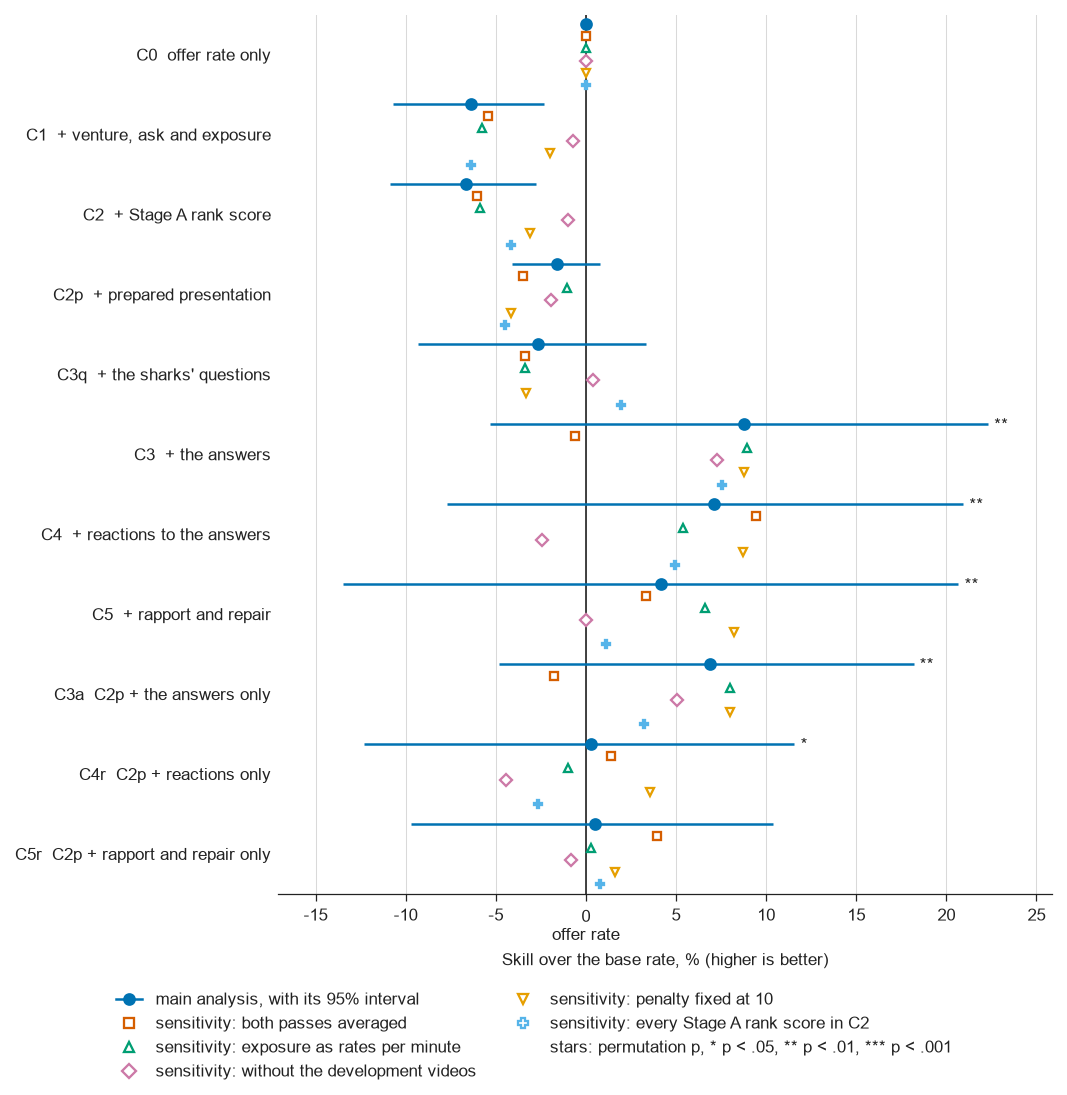

In [37]:
fig = pf.figure(A, 1, FIGURE_WIDTH)
print(pf.caption(A, 1, FIGURE_WIDTH))

### Figure 2. AUC per model

Figure 2. AUC of each model of the ladder. Area under the ROC curve of the held-out scores of the models of Figure 1 (C0 to C5 with C2p and C3q). Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. Bars are 95% percentile intervals from resampling whole pitches (1999 draws) of the fixed held-out predictions (models are not refitted in a draw, so the intervals understate the uncertainty). Stars come from the pitch-level permutation test with 500 permutations (the pitch outcomes are shuffled across pitches and the whole leave-one-pitch-out fit is repeated); p = (1 + permutations at least as good) / (1 + 500). * p < .05, ** p < .01, *** p < .001. How to read it: the vertical line at 0.5 is chance; right of it a model ranks pitches with an offer above pitches without. Every finite AUC is drawn; a hollow grey marker is a model whose held-out predictions stay w

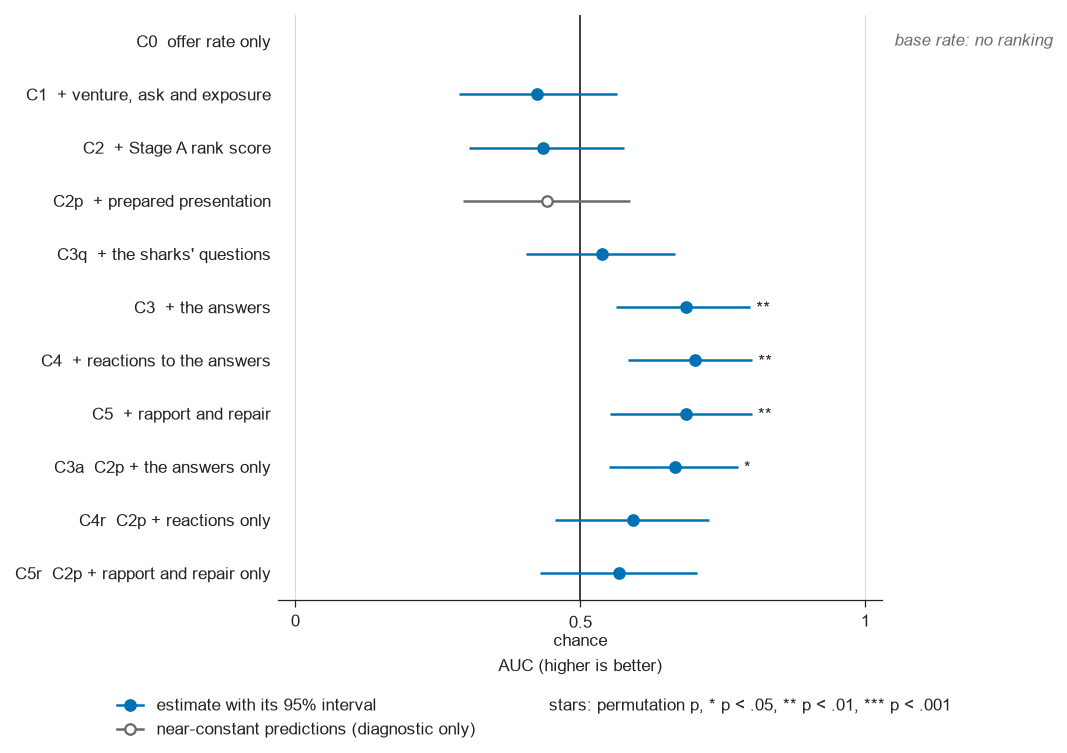

In [38]:
fig = pf.figure(A, 2, FIGURE_WIDTH)
print(pf.caption(A, 2, FIGURE_WIDTH))

### Figure 3. ROC curves

Figure 3. ROC curves of the base-rate-adjusted held-out score. ROC curves of every model with features, drawn on the base-rate-adjusted held-out score (the score its AUC ranks; AUCs rank the base-rate-adjusted held-out score logit(p) - logit(b), b the training base rate of the pitch's fold, which reduces the leave-one-pitch-out artefact of a model near the base rate (a residual bias against weak models remains: a weak model can still score below 0.5); they are not comparable with the AUCs of earlier (v3-dev8) analyses), pitches weighted equally. Each model has its own dash pattern and colour, with its AUC and the p-value of that AUC in the legend; the dotted diagonal is chance; 'near-constant' in the legend marks a model whose held-out predictions stay within about 3 points of the offer rate (a diagnostic only; see Figure 2). Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are explorat

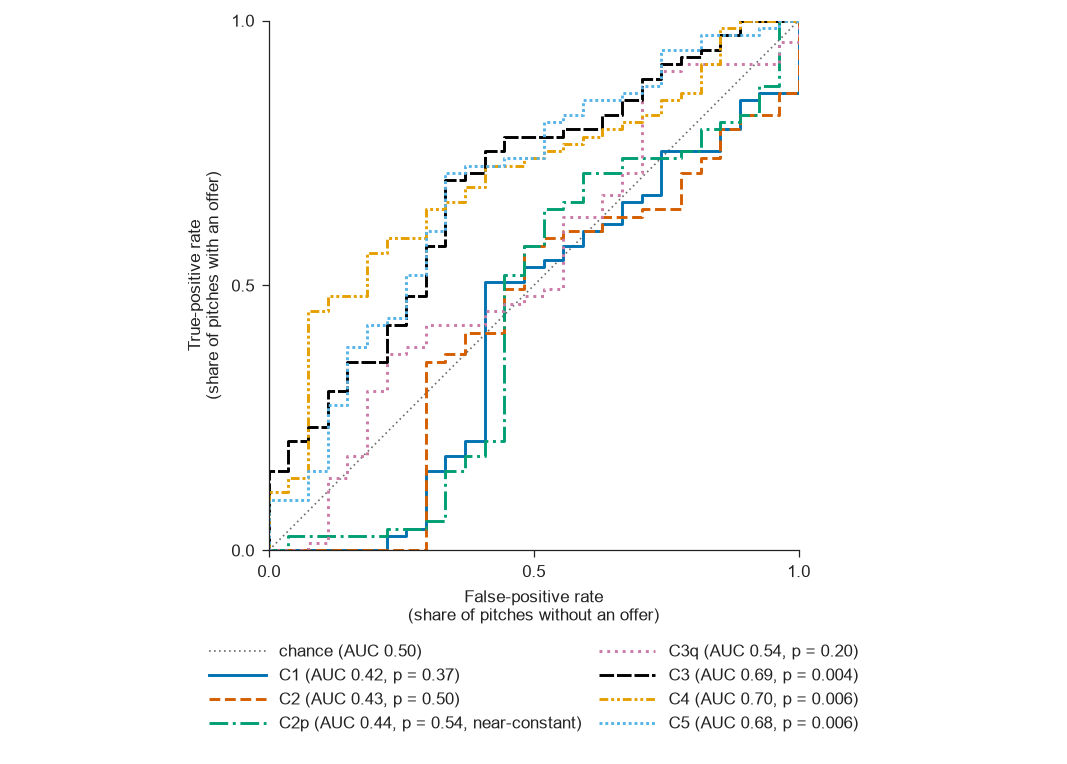

In [39]:
fig = pf.figure(A, 3, FIGURE_WIDTH)
print(pf.caption(A, 3, FIGURE_WIDTH))

### Figure 4. Each concept on its own

Figure 4. Each pitch feature on its own. Each pitch feature on its own: its correlation with any offer, one row per feature, grouped by family and sorted by size within a family; the 20 features with the largest correlation are shown, columns that only count the observations behind a mean are left out. Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. Bars are 95% percentile intervals from resampling whole pitches (9999 draws). Markers show significance: two-sided pitch-level permutation p-values of the correlation, adjusted for the 77 features ranked with the Benjamini-Hochberg false-discovery rate; a filled triangle survives the adjustment (q < 0.05), a hollow triangle has p < 0.05 before adjustment only, a grey circle has neither (5 of 77 features survive). How to read it: right of 0, more of the feature goes with an offer. Each feature is looked at 

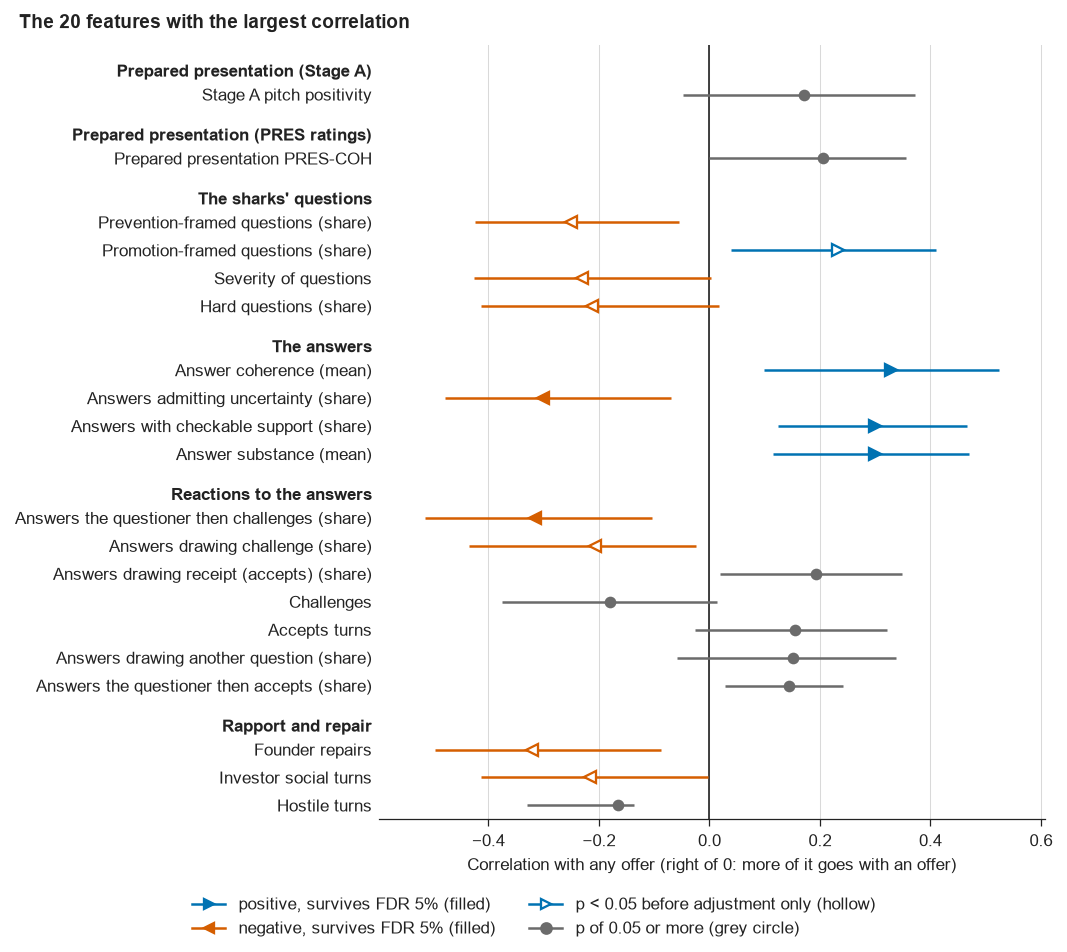

In [40]:
fig = pf.figure(A, 4, FIGURE_WIDTH)
print(pf.caption(A, 4, FIGURE_WIDTH))

### Figure 5. Answer quality by outcome

Figure 5. Substance and checkable support of the answers, by any offer. Answer quality by any offer, from the answers to all sharks' questions before the pitch's cut, pooled per pitch: the mean substance (1 to 5) and the percentage of answers with checkable support, for answers to all questions and to hard questions only (severity 2 to 3); n is the number of pitches with a value (substance / support). Panels A and C: the mean among pitches with an offer (filled blue circle) and without (hollow vermillion square). Panels B and D: the correlation of each measure with any offer. Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. Bars in B and D are 95% percentile intervals from resampling whole pitches (9999 draws). Markers: two-sided pitch-level permutation p-values, Benjamini-Hochberg-adjusted over the 4 rows of this table (filled: q < 0.05; hollow: p < 0

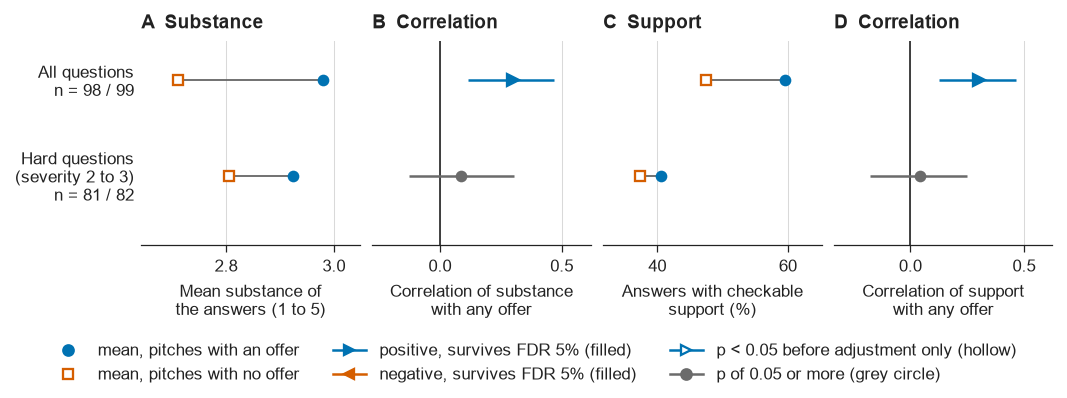

In [41]:
fig = pf.figure(A, 5, FIGURE_WIDTH)
print(pf.caption(A, 5, FIGURE_WIDTH))

### Figure 6. Calibration

Figure 6. Calibration of the held-out predictions. Calibration of the held-out predictions of every model with features. Per model the pitches are sorted by predicted probability into four equal groups; a point is a group's mean prediction against the share of its pitches with an offer. Each model has its own marker and dash pattern; the dotted diagonal is perfect calibration. Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. No intervals or tests are drawn: each point rests on a quarter of the pitches (the models' intervals, from 1999 resamples of whole pitches, are in Figure 1). How to read it: points on the diagonal mean that a predicted 30% came true for about 30% of the pitches; a flat line means the predictions hardly separate the groups.


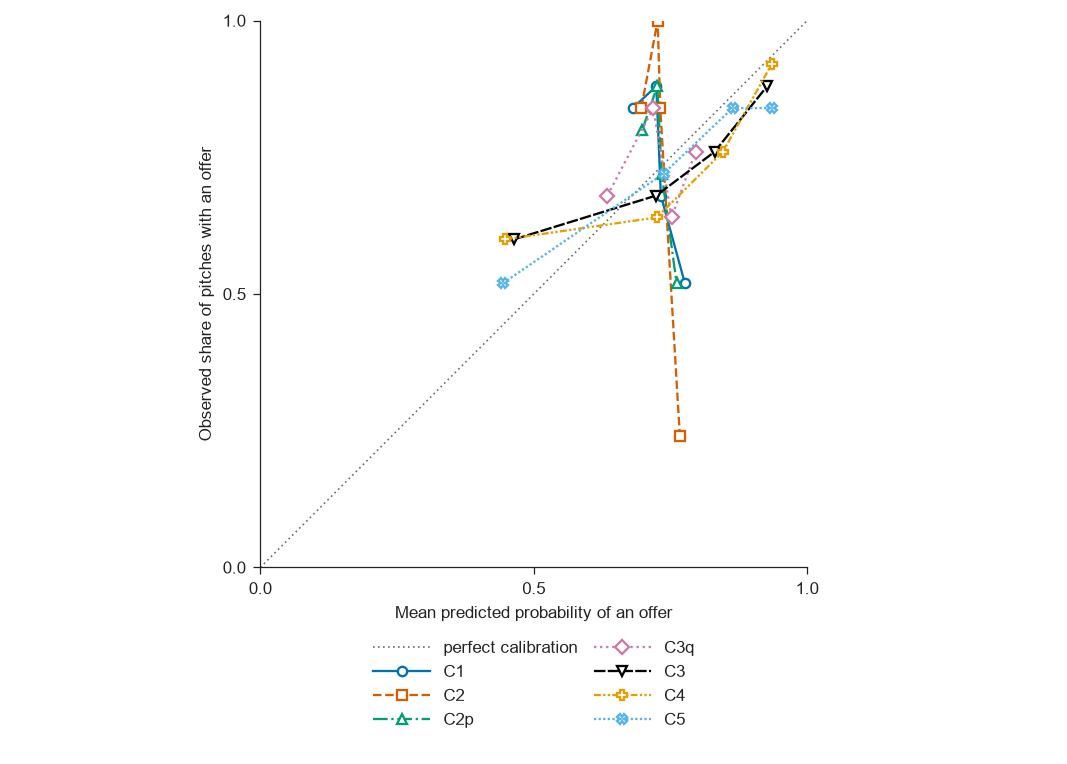

In [42]:
fig = pf.figure(A, 6, FIGURE_WIDTH)
print(pf.caption(A, 6, FIGURE_WIDTH))

### Figure 7. What the panel does after an answer

Figure 7. What the panel does after an answer, by checkable support (H4). What the panel does after an answer (H4): the percentage of answers whose first reaction by any shark is a receipt (an accepts turn), another question, or a challenge, for answers that give checkable support (filled blue circle) and answers that give none (hollow vermillion square). Panel A: answers to all questions (863 with support, 682 without); panel B: answers to hard questions, severity 2 to 3 (120 and 190). One unit is an answer and a shark's question it responds to, over the whole encounter of 100 pitches (no cut). Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. Bars are 95% percentile intervals from resampling whole pitches (1999 draws). The numbers above each pair are the difference, with support minus without, in percentage points, with its interval; its stars are the

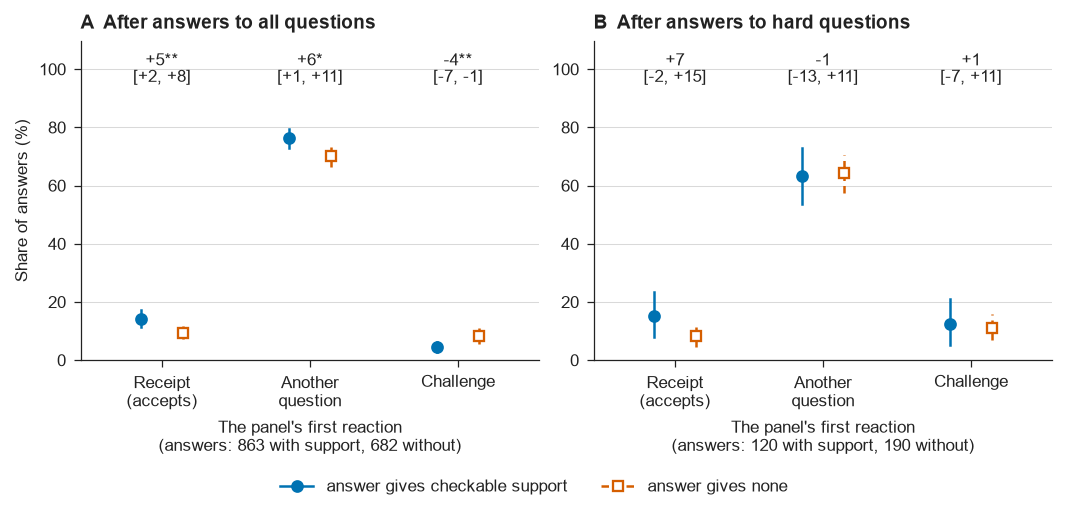

In [43]:
fig = pf.figure(A, 7, FIGURE_WIDTH)
print(pf.caption(A, 7, FIGURE_WIDTH))

### Figure 8. Coefficients of the full model C5

Figure 8. Coefficients of the full model C5. Coefficients of the full model C5 refitted on all pitches with a known outcome: the 20 largest of 85, grouped by feature family. A coefficient is the change in the log-odds of an offer per one standard deviation of the feature (per level of a category) in a ridge-penalised logistic model whose penalty is fixed at 10, the value the leave-one-pitch-out run chose most often. Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. Bars are 95% percentile intervals from resampling whole pitches and refitting the model (1999 draws); a hollow triangle has a two-sided bootstrap p below 0.05 (blue pointing right: positive; vermillion pointing left: negative), a grey circle has not; these p-values are not adjusted for the number of coefficients. How to read it: these are conditional associations within one penalised model, n

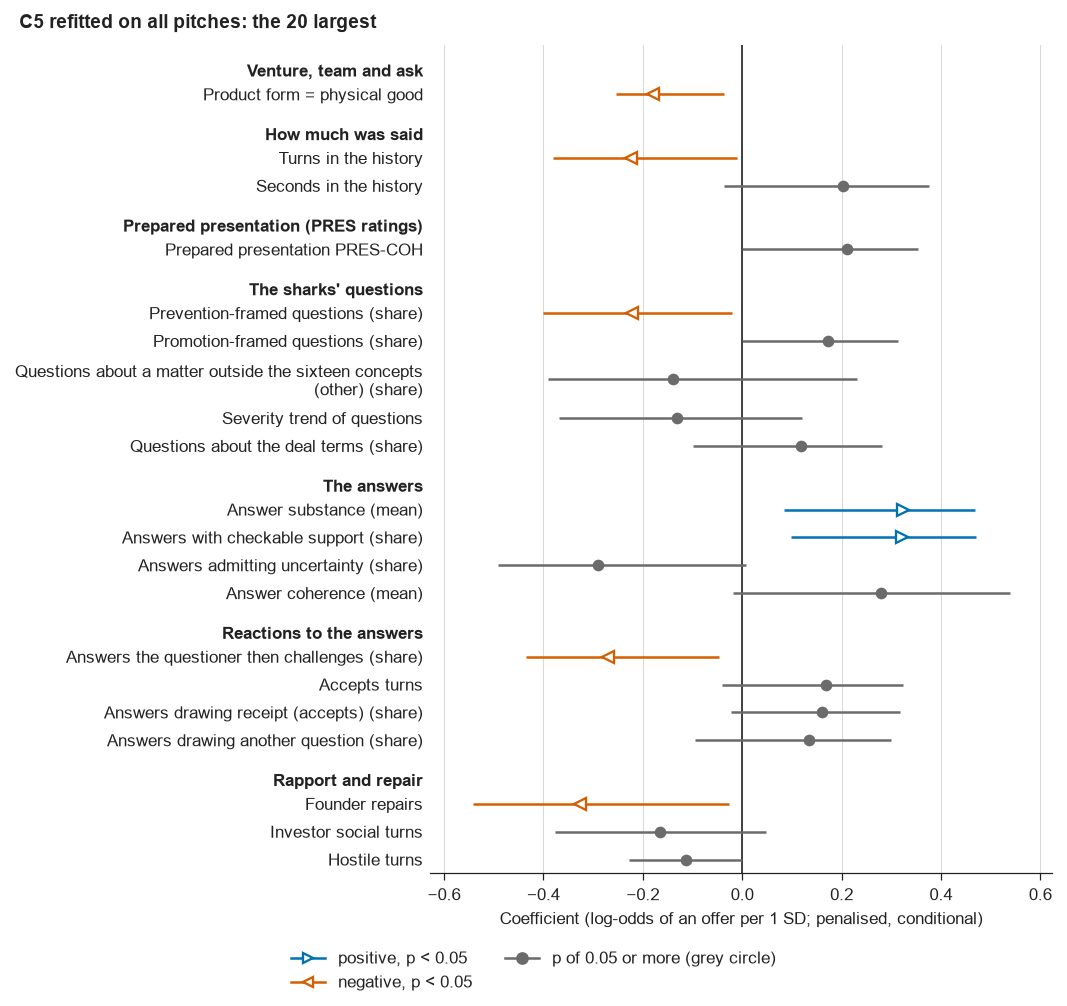

In [44]:
fig = pf.figure(A, 8, FIGURE_WIDTH)
print(pf.caption(A, 8, FIGURE_WIDTH))

### Figure 9. H9: a prepared answer and the next move

Figure 9. H9: what follows an answer, coefficients with intervals for all and hard questions. H9, the answer-level test: what follows an answer, by the answer's ratings, within pitch. Panel A: answers to all questions; panel B: answers to hard questions (severity 2 or 3). Each nested model has its own marker: support (checkable support and admitted uncertainty, all answers), substance (+ substance, answers with a substance rating), full (+ coherence and context, answers rated on all five; the context rating is Gemini only, not human-coded) and responsiveness (admitted uncertainty and repair before the next turn, all answers). One row of axes per unit: the binary next moves, among them whether the next investor question keeps the promotion/prevention frame of the question answered (log-odds from a conditional logit within pitch), the severity of the next question, and the number of further questions in turn order that keep that frame (each a change in that outcome from pitch fixed effec

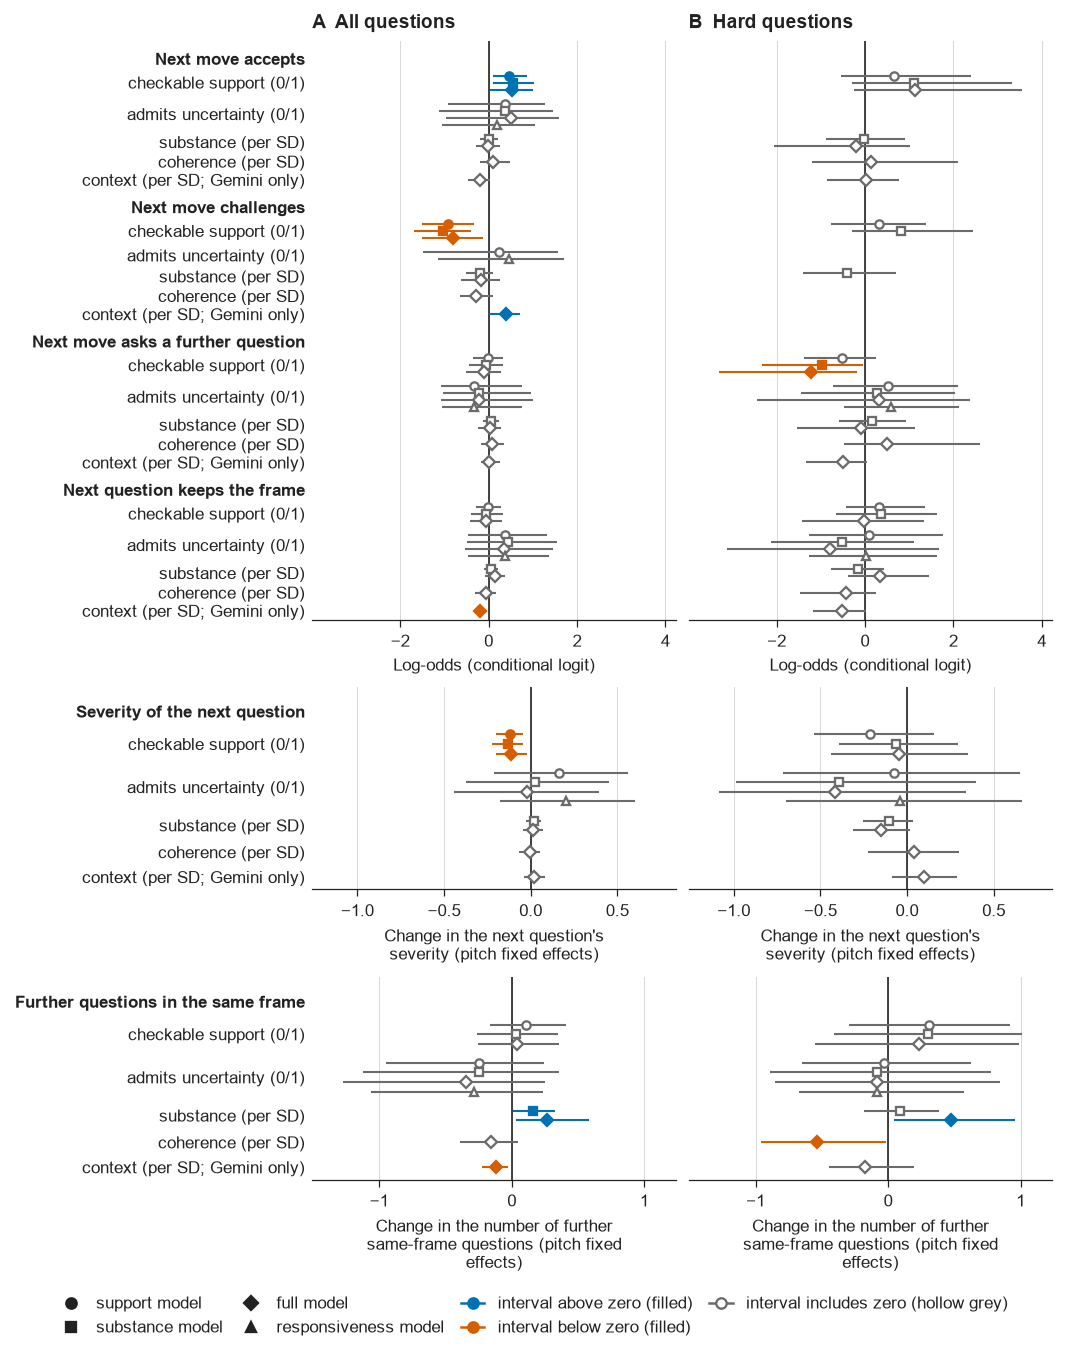

In [45]:
fig = pf.figure(A, 9, FIGURE_WIDTH)
print(pf.caption(A, 9, FIGURE_WIDTH))

### Figure 10. Each family's gain over the baseline in ranking, alone and cumulative

Figure 10. Ranking: the baseline C2p and each family's gain over it, alone and cumulative. The baseline model C2p (the venture, the ask, exposure, the Stage A rank score and the prepared presentation; 44 pairs ranked correctly per 100) in the first row as a black diamond, and below it each family's models at their own level, each with its 95% interval. Of 100 pairs of one funded and one unfunded pitch, how many each model ranks correctly (AUC x 100; the dotted line at 50 is chance), with the gains written as percentage points of pairs. A filled blue circle is the family entering alone (C2p plus that family: C3q, C3a, C4r, C5r; spec amendment 6.9 of 2026-10-25); a hollow vermillion square is the same family entering the cumulative ladder on top of the families before it (C3q, C3, C4, C5). For the questions the two are the same model and are drawn once. The solid vertical line is the baseline's value, so a point's distance from it is the family's gain over the baseline; beside each point

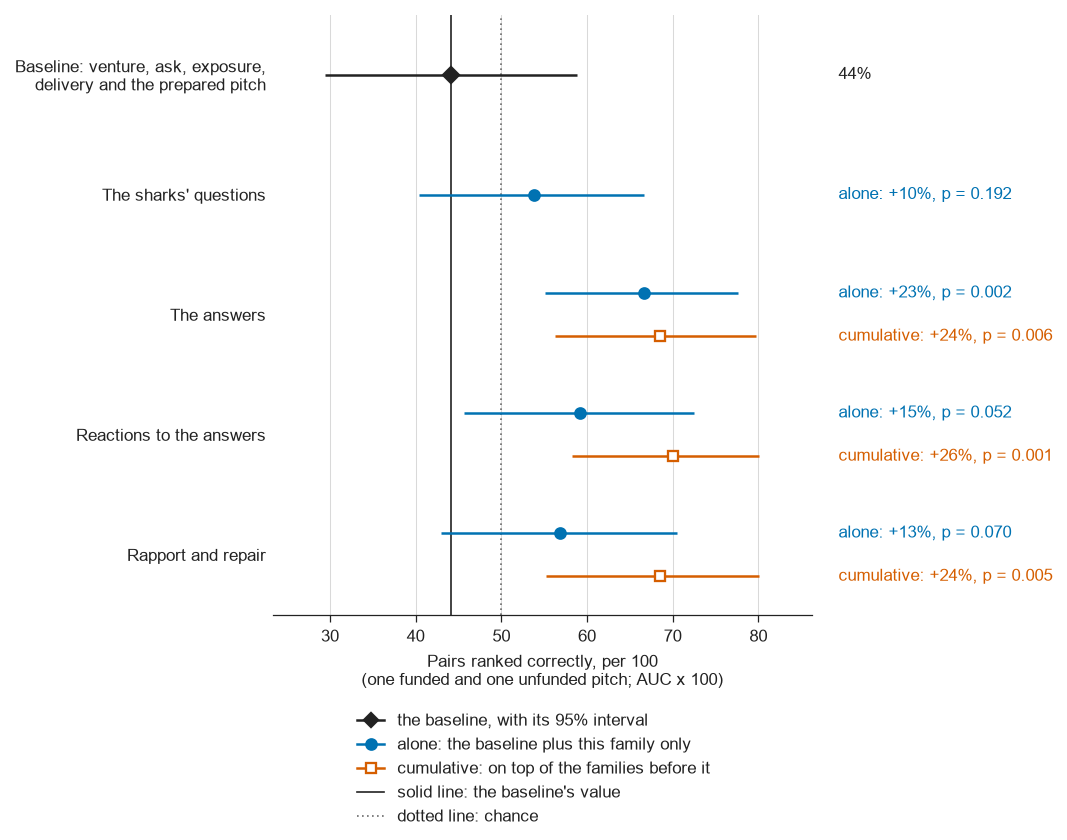

In [46]:
fig = pf.figure(A, 10, FIGURE_WIDTH)
print(pf.caption(A, 10, FIGURE_WIDTH))

### Supplementary figure S1. The archived shark-level ladder (F1)

Supplementary Figure S1. Shark-level ladder (archived design): skill over the base rate. The archived shark-level design (one row per investor, outcome: does this shark offer), rerun on the same records with --with-shark-level for the F1 paragraph: skill over the base rate of each model B0 to B5d, fitted leaving one pitch out, with 95% percentile intervals from resampling whole pitches (1999 draws) of the fixed held-out predictions. 100 pitches, 483 shark rows (pitch-held-out estimate). Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. This figure is reported, not tested: the pre-registered test is the pitch-level ladder of Figure 1. How to read it: a point right of 0 predicts each held-out shark's decision better than the offer rate; sharks of one pitch are not independent, so the intervals resample pitches.


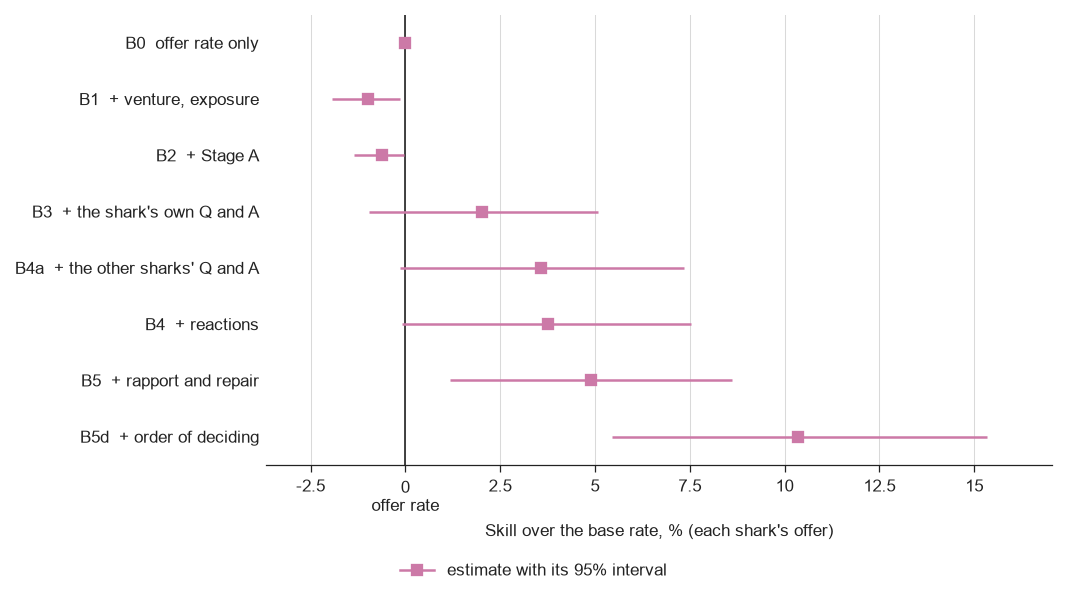

In [47]:
fig = pf.figure(A, "S1", FIGURE_WIDTH)
print(pf.caption(A, "S1", FIGURE_WIDTH))

### Supplementary figure S2. Each family's gain over the baseline in skill

Supplementary Figure S2. Skill: the baseline C2p and each family's gain over it, alone and cumulative. The baseline model C2p (the venture, the ask, exposure, the Stage A rank score and the prepared presentation; skill -1.6%) in the first row as a black diamond, and below it each family's models at their own level, each with its 95% interval. Skill over the base rate, in percent (the dotted line at 0 is guessing the offer rate for every pitch); the axis is held to -10 to 12 so that the models can be told apart, and an interval that runs past an edge is cut there and marked with an arrowhead (the full intervals are in metrics.csv). A filled blue circle is the family entering alone (C2p plus that family: C3q, C3a, C4r, C5r; spec amendment 6.9 of 2026-10-25); a hollow vermillion square is the same family entering the cumulative ladder on top of the families before it (C3q, C3, C4, C5). For the questions the two are the same model and are drawn once. The solid vertical line is the baseline

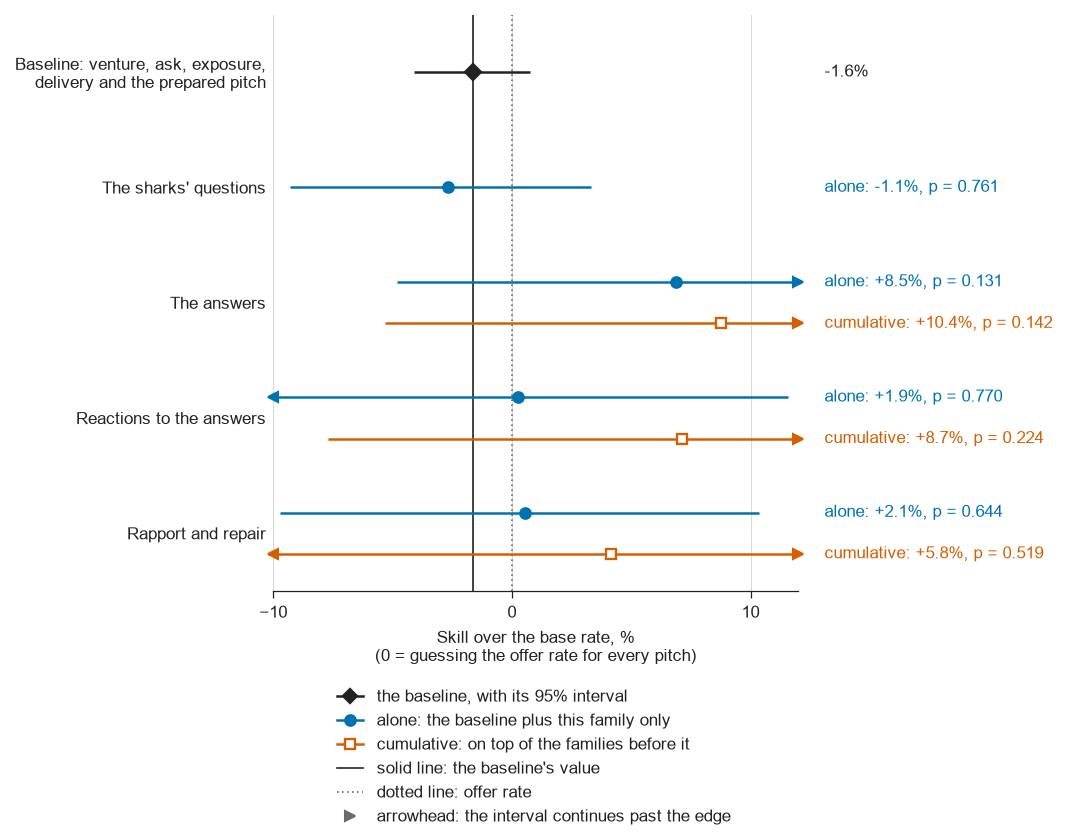

In [48]:
fig = pf.figure(A, "S2", FIGURE_WIDTH)
print(pf.caption(A, "S2", FIGURE_WIDTH))

### Where the figure files are

This cell writes the figures when `SAVE_FIGURES = True` (with `EXPORT = True` section 14 has already written them),
then lists every figure file in the folder with its caption. With both settings `False` it writes nothing and lists
what an earlier export left there.

In [49]:
if SAVE_FIGURES and not EXPORT:
    pr.save_figures(A, ANALYSIS_ID, FIGURE_WIDTH)
print(pr.files_note(A, ANALYSIS_ID, EXPORT or SAVE_FIGURES))
px.show(pr.figure_files(A, ANALYSIS_ID), "No figure file to list.", whole=True)

EXPORT and SAVE_FIGURES are False: nothing was written. The 12 figures listed below are already in runs/full-corpus-100/analysis/all100/figures/ from an earlier export (they may come from other settings than this execution's).


Figure,What it shows,Files,Caption file,Caption
1,"Model ladder: skill over the base rate of C0 to C5 with C2p and C3q, and the sensitivities","figure_1_model_ladder.png, figure_1_model_ladder.pdf",figure_1_caption.md,"Figure 1. Model ladder: skill over the base rate of C0 to C5 with C2p and C3q, and the sensitivities. Skill over the base rate, 100 x (1 - log loss / log loss of always predicting the offer rate), of each model of the pre-registered ladder, fitted leaving one pitch out; one row per pitch, outcome any offer. The ladder adds one step at a time: C1 the venture, ask and exposure; C2 the primary Stage A rank score; C2p the prepared presentation; C3q the sharks' questions; C3 the answers; C4 the reactions; C5 rapport and repair. Models: C0 (no features), C1 (control+exposure), C2 (control+exposure+sa_rank_pitch_positivity), C2p (control+exposure+sa_rank_pitch_positivity+prepared), C3q (control+exposure+sa_rank_pitch_positivity+prepared+questions), C3 (control+exposure+sa_rank_pitch_positivity+prepared+questions+answers), C4 (control+exposure+sa_rank_pitch_positivity+prepared+questions+answers+reactions), C5 (control+exposure+sa_rank_pitch_positivity+prepared+questions+answers+reactions+rapport_repair), C3a (control+exposure+sa_rank_pitch_positivity+prepared+answers), C4r (control+exposure+sa_rank_pitch_positivity+prepared+reactions), C5r (control+exposure+sa_rank_pitch_positivity+prepared+rapport_repair). Hollow markers below each filled one are the same model under each sensitivity (point estimates only): both passes averaged (s); exposure as rates per minute (^); without the development videos (D); penalty fixed at 10 (v); every Stage A rank score in C2 (P). Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. Bars are 95% percentile intervals from resampling whole pitches (1999 draws) of the fixed held-out predictions (models are not refitted in a draw, so the intervals understate the uncertainty). Stars come from the pitch-level permutation test with 500 permutations (the pitch outcomes are shuffled across pitches and the whole leave-one-pitch-out fit is repeated); p = (1 + permutations at least as good) / (1 + 500). * p < .05, ** p < .01, *** p < .001. How to read it: the vertical line at 0 is a model that knows only the offer rate; a point to its right predicts held-out pitches better, and a bar that crosses the line means this sample does not show a difference from the offer rate. The verdicts of H1' (C3 against C2p) and H8 (C3 against C3q) rest on the paired differences in report.md, not on overlapping bars. The p-values describe this sample of model-coded videos; they are not confirmatory tests (the pre-registered verdicts are in report.md)."
2,AUC of each model of the ladder,"figure_2_auc_per_model.png, figure_2_auc_per_model.pdf",figure_2_caption.md,"Figure 2. AUC of each model of the ladder. Area under the ROC curve of the held-out scores of the models of Figure 1 (C0 to C5 with C2p and C3q). Sample: 100 pitches with a known outcome, 73 with at least one offer, of 100 analysed. All annotations are model-coded (no human review); the results are exploratory, not confirmatory. Bars are 95% percentile intervals from resampling whole pitches (1999 draws) of the fixed held-out predictions (models are not refitted in a draw, so the intervals understate the uncertainty). Stars come from the pitch-level permutation test with 500 permutations (the pitch outcomes are shuffled across pitches and the whole leave-one-pitch-out fit is repeated); p = (1 + permutations at least as good) / (1 + 500). * p < .05, ** p < .01, *** p < .001. How to read it: the vertical line at 0.5 is chance; right of it a model ranks pitches with an offer above pitches without. Every finite AUC is drawn; a hollow grey marker is a model whose held-out predictions stay within about 3 points of the offer rate, a diagn